# UTFormer on ISCX-VPN-2016 — replication + 3 novelties + explainability

**One notebook, top to bottom.** It rebuilds the data pipeline correctly, trains UTFormer-style models with attention-based *Dynamic Payload Distillation* (DPD), runs the three novelty studies and the explainability analyses, and writes every figure and table for the paper into one folder (also zipped and copied to Drive).

| | What it does | Output |
|---|---|---|
| **DAS (Algorithm 1)** | Differentiable architecture search over {heads, layers, FFN size, γ} with the unified accuracy + FLOPs loss (Eqs. 4–11), convergence plots and the α:β coefficient study | Tables 9–11, Figs 14–16 |
| **Replication** | 6-class ISCX service classification, DPD on class-token attention; the **searched architecture**, the paper-reported one (1 layer, 4 heads, FFN 268, γ = 5 %) and a 2-layer variant | Tables 1–2, Figs 2–4 |
| **Novelty 1 — DPD scoring rules** | Paper's head-mean vs head-max, received-attention, attention×‖value‖, learned gate, random, at several keep rates | Table 3, Figs 5–6 |
| **Novelty 2 — leakage-aware evaluation** | Packet-level vs flow-segment-level vs held-out-capture splits | Table 4, Fig 7 |
| **Novelty 3 — header reliance** | Mask IP header / IP+L4 header / first 96 B / payload and measure the drop | Table 5, Fig 8 |
| **Explainability** | Per-class importance heatmaps, protocol-field mass, kept-token examples, deletion/insertion faithfulness (incl. Integrated Gradients), agreement between scoring rules | Tables 6–7, Figs 9–13 |

**Deviations from the paper (state these in the paper):**
1. **DAS is implemented in full but with three documented choices the paper leaves open:** the gradient of the validation loss w.r.t. the integer parameters is estimated with SPSA; the SGD step is normalised (the paper's lr = 0.005 does not move the parameters — our first attempt showed this); the search trains on a subset. A 2-layer fixed model is also kept, because with one layer DPD can only save FFN compute (the class token has already attended to every token).
2. Splits are by *flow segment* (consecutive packets of one 5-tuple) because VPN captures are a handful of tunnel flows; a held-out-capture protocol is added.
3. Epochs/seeds are reduced for a one-day budget, and the search uses 15 iterations × 4 epochs on a subset (`CFG` below).
4. The 10 Gbps DPDK testbed is not reproduced; throughput is measured offline.

Set `QUICK = True` in the next cell for a ~5-minute smoke test. Use a **GPU runtime** (Runtime → Change runtime type → T4).

In [ ]:
import os, io, sys, re, gc, json, math, time, copy, random, struct, shutil, subprocess, warnings, itertools
from pathlib import Path
from collections import Counter
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
import torch, torch.nn as nn, torch.nn.functional as F
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, precision_recall_fscore_support, confusion_matrix
warnings.filterwarnings('ignore')
try:
    from IPython.display import display
except Exception:
    display = print

IN_COLAB = False
try:
    from google.colab import drive
    drive.mount('/content/drive')
    IN_COLAB = True
    subprocess.run('apt-get -qq install -y p7zip-full > /dev/null 2>&1', shell=True)
except Exception as e:
    print('Colab Drive mount skipped:', e)

# ------------------------------------------------------------------ settings
QUICK = False          # True = tiny smoke test (~5 min); False = full run
CFG = dict(
    archive_scope='auto',        # 'vpn' | 'nonvpn' | 'both' | 'auto' (VPN first, add NonVPN if <5 classes)
    zip_paths=None,              # or an explicit list of zip paths
    search_root='/content/drive/MyDrive',
    pkt_len=1500, patch=16, seg_len=100, scan_limit=250_000,
    per_member_cap=3000, per_class_cap=6000, min_class_pkts=400,
    seeds=[0, 1, 2], sweep_seeds=[0, 1],
    epochs=20, sweep_epochs=10, batch=256, lr=1e-3,
    dim=64, heads=4, layers=2, ffn=128, drop=0.1,
    paper_layers=1, paper_heads=4, paper_ffn=268, paper_gamma=0.05,
    main_gamma=0.2, keep_rates=[0.5, 0.2, 0.1, 0.05],
    n_explain_per_class=100, ig_steps=8,
    das_iters=15, das_epochs=4, das_train_n=15000, das_val_n=4000, das_alpha=0.5, das_beta=1.5,
    das_init=[0.34, 0.34, 0.35, 0.5],       # start point in normalised space: (4 heads, 4 layers, d=358, gamma=0.5)
    das_lr=0.15, das_lr_decay=0.85, das_c=0.12, das_patience=3, das_cost_extra_gamma=True,
    das_coef_study=True, das_iters_coef=10, das_coefs=[(3, 1), (2, 1), (1, 1), (0.5, 1)],
    out_dir='/content/UTFormer_Novelty_Results',
)
if QUICK:
    CFG.update(scan_limit=30_000, per_member_cap=400, per_class_cap=1500, min_class_pkts=150,
               seeds=[0], sweep_seeds=[0], epochs=3, sweep_epochs=2, keep_rates=[0.5, 0.1],
               n_explain_per_class=40, ig_steps=4, das_iters=3, das_epochs=1, das_train_n=2500, das_val_n=1000,
               das_coef_study=False, das_iters_coef=2)

DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
USE_AMP = DEVICE.type == 'cuda'
print('Device:', DEVICE, '| mixed precision:', USE_AMP, '| QUICK:', QUICK)
if DEVICE.type == 'cpu':
    print('WARNING: no GPU found. Use Runtime > Change runtime type > T4 GPU, or set QUICK=True.')

OUT = CFG['out_dir']; FIG = OUT + '/figures'; TAB = OUT + '/tables'
for d in (OUT, FIG, TAB): os.makedirs(d, exist_ok=True)
plt.rcParams.update({'figure.dpi': 110, 'savefig.dpi': 200, 'font.size': 10, 'axes.grid': True,
                     'grid.alpha': .25, 'axes.spines.top': False, 'axes.spines.right': False})

def seed_all(s):
    random.seed(s); np.random.seed(s); torch.manual_seed(s)
    if torch.cuda.is_available(): torch.cuda.manual_seed_all(s)

def savefig(name):
    plt.tight_layout()
    plt.savefig(f'{FIG}/{name}.png', bbox_inches='tight')
    plt.savefig(f'{FIG}/{name}.pdf', bbox_inches='tight')
    plt.show()

def save_table(df, name, index=False, show=True):
    df.to_csv(f'{TAB}/{name}.csv', index=index)
    try:
        df.to_latex(f'{TAB}/{name}.tex', index=index, float_format='%.3f')
    except Exception as e:
        print('LaTeX export skipped for', name, ':', e)
    if show: display(df)
    return df

Mounted at /content/drive
Device: cuda | mixed precision: True | QUICK: False


## 1. PCAP / PCAPNG reading and pre-processing (fixed)

Differences from the earlier notebooks:
* IP addresses and ports are masked with **real zero bytes** (`bytes(n)`); the earlier `b'\\x00'` literal inserted text and shifted the packet.
* The TCP filter removes SYN/FIN/RST packets and **zero-payload** TCP packets (handshake/teardown/pure ACK). Data packets that merely carry the ACK flag are kept — the earlier mask dropped almost every TCP packet.
* A **flow key** (bidirectional 5-tuple) and a **segment index** (every `seg_len` consecutive packets of a flow) are recorded *before* masking, so we can split by flow segment.
* PCAPNG files are supported (several ISCX captures are `.pcapng`).

In [ ]:
def iter_pcap(stream):
    head = stream.read(4)
    if len(head) < 4: return
    if head == b'\x0a\x0d\x0d\x0a':
        yield from _iter_pcapng(stream, head); return
    magics = {b'\xd4\xc3\xb2\xa1': '<', b'\xa1\xb2\xc3\xd4': '>', b'\x4d\x3c\xb2\xa1': '<', b'\xa1\xb2\x3c\x4d': '>'}
    if head not in magics: raise ValueError('Unsupported capture magic ' + head.hex())
    e = magics[head]
    rest = stream.read(20)
    if len(rest) < 20: return
    link = struct.unpack(e + 'I', rest[16:20])[0] & 0x0FFFFFFF
    while True:
        rh = stream.read(16)
        if len(rh) < 16: return
        _, _, incl, _ = struct.unpack(e + 'IIII', rh)
        if incl > 1 << 22: return
        fr = stream.read(incl)
        if len(fr) < incl: return
        yield link, fr

def _iter_pcapng(stream, first4):
    endian, ifaces, pending = '<', [], first4
    while True:
        if pending is not None:
            t, pending = pending, None
        else:
            t = stream.read(4)
            if len(t) < 4: return
        lb = stream.read(4)
        if len(lb) < 4: return
        if t == b'\x0a\x0d\x0d\x0a':
            bom = stream.read(4)
            if len(bom) < 4: return
            endian = '<' if bom == b'\x4d\x3c\x2b\x1a' else '>'
            total = struct.unpack(endian + 'I', lb)[0]
            if total < 12: return
            stream.read(total - 12); ifaces = []
            continue
        total = struct.unpack(endian + 'I', lb)[0]
        if total < 12 or total > 1 << 26: return
        body = stream.read(total - 8)          # body + trailing length field
        if len(body) < total - 8: return
        body = body[:-4]
        btype = struct.unpack(endian + 'I', t)[0]
        if btype == 1 and len(body) >= 4:
            ifaces.append(struct.unpack(endian + 'H', body[:2])[0])
        elif btype == 6 and len(body) >= 20:
            iid, _, _, cap, _ = struct.unpack(endian + 'IIIII', body[:20])
            fr = body[20:20 + cap]
            if len(fr) == cap and iid < len(ifaces): yield ifaces[iid], fr
        elif btype == 3 and len(body) >= 4 and ifaces:
            orig = struct.unpack(endian + 'I', body[:4])[0]
            yield ifaces[0], body[4:4 + min(orig, len(body) - 4)]

def extract_ip(frame, link):
    if link in (101, 12, 14):
        return frame if frame and (frame[0] >> 4) in (4, 6) else None
    if link == 113:                              # Linux cooked capture
        if len(frame) < 16: return None
        return frame[16:] if int.from_bytes(frame[14:16], 'big') in (0x0800, 0x86DD) else None
    if link != 1 or len(frame) < 14: return None
    off, et = 14, int.from_bytes(frame[12:14], 'big')
    while et in (0x8100, 0x88A8, 0x9100):
        if len(frame) < off + 4: return None
        et = int.from_bytes(frame[off + 2:off + 4], 'big'); off += 4
    return frame[off:] if et in (0x0800, 0x86DD) else None

ZERO2 = b'\x00\x00'
def preprocess(ip):
    # returns (uint8[pkt_len], true_len, flow_key) or None if the packet is filtered out
    L = CFG['pkt_len']; n = len(ip)
    if n < 20: return None
    v = ip[0] >> 4
    if v == 4:
        ihl = (ip[0] & 15) * 4
        if ihl < 20 or n < ihl: return None
        proto = ip[9]
        if proto == 1: return None                                   # ICMP
        tot = int.from_bytes(ip[2:4], 'big')
        frag = int.from_bytes(ip[6:8], 'big') & 0x1FFF
        src, dst = bytes(ip[12:16]), bytes(ip[16:20])
        sp = dp = ZERO2
        l4 = proto in (6, 17) and frag == 0 and n >= ihl + 4
        if l4: sp, dp = bytes(ip[ihl:ihl + 2]), bytes(ip[ihl + 2:ihl + 4])
        if proto == 6 and frag == 0:
            if n < ihl + 20: return None
            flags, thl = ip[ihl + 13], (ip[ihl + 12] >> 4) * 4
            if flags & 0x07: return None                              # FIN / SYN / RST
            if min(tot, n) - ihl - thl <= 0: return None              # no payload (pure ACK)
        b = bytearray(ip[:L])
        b[12:20] = bytes(8)
        if l4 and len(b) >= ihl + 4: b[ihl:ihl + 4] = bytes(4)
    elif v == 6:
        if n < 40: return None
        nh = ip[6]
        if nh == 58: return None                                      # ICMPv6
        src, dst = bytes(ip[8:24]), bytes(ip[24:40])
        sp = dp = ZERO2
        l4 = nh in (6, 17) and n >= 44
        if l4: sp, dp = bytes(ip[40:42]), bytes(ip[42:44])
        if nh == 6:
            if n < 60: return None
            flags, thl = ip[53], (ip[52] >> 4) * 4
            if flags & 0x07: return None
            if min(int.from_bytes(ip[4:6], 'big'), n - 40) - thl <= 0: return None
        b = bytearray(ip[:L])
        b[8:40] = bytes(32)
        if l4 and len(b) >= 44: b[40:44] = bytes(4)
        proto = nh
    else:
        return None
    ends = sorted([(src, sp), (dst, dp)])
    arr = np.zeros(L, dtype=np.uint8)
    arr[:len(b)] = np.frombuffer(bytes(b), dtype=np.uint8)
    return arr, min(n, L), (proto, ends[0], ends[1])

def parse_stream(stream, cap, scan_limit, seg_len, seed):
    rng = random.Random(seed); res = []; seen = 0; fids = {}; fcnt = Counter()
    for link, fr in iter_pcap(stream):
        ip = extract_ip(fr, link)
        if ip is None: continue
        out = preprocess(ip)
        if out is None: continue
        arr, plen, key = out
        fid = fids.setdefault(key, len(fids))
        seg = fcnt[fid] // seg_len; fcnt[fid] += 1
        item = (arr, plen, fid, seg); seen += 1
        if len(res) < cap: res.append(item)
        else:
            j = rng.randrange(seen)
            if j < cap: res[j] = item
        if seen >= scan_limit: break
    return res, seen

def read_member(zip_path, member, seed):
    proc = subprocess.Popen(['7z', 'x', '-so', zip_path, member], stdout=subprocess.PIPE,
                            stderr=subprocess.DEVNULL, bufsize=1 << 20)
    try:
        return parse_stream(proc.stdout, CFG['per_member_cap'], CFG['scan_limit'], CFG['seg_len'], seed)
    finally:
        try: proc.kill()
        except Exception: pass
        try: proc.stdout.close()
        except Exception: pass
        proc.wait()

def list_members(zip_path):
    txt = subprocess.run(['7z', 'l', '-slt', zip_path], capture_output=True, text=True).stdout
    out = []
    for blk in txt.split('\n\n'):
        d = {}
        for line in blk.splitlines():
            if ' = ' in line:
                k, v = line.split(' = ', 1); d[k.strip()] = v.strip()
        p = d.get('Path', '')
        if p.lower().endswith(('.pcap', '.pcapng', '.cap')) and d.get('Folder', '-') != '+' \
           and '__MACOSX' not in p and d.get('Size', '1') != '0':
            out.append(p)
    return out

def service_of(name):
    n = os.path.basename(name).lower()
    if 'email' in n: return 'Email'
    if 'torrent' in n: return 'P2P'
    if 'chat' in n: return 'Chat'
    if any(k in n for k in ('ftp', 'scp', '_file', 'file_transfer')): return 'FileTransfer'
    if any(k in n for k in ('netflix', 'spotify', 'vimeo', 'youtube')): return 'Streaming'
    if any(k in n for k in ('audio', 'voipbuster', 'video')): return 'VoIP'
    return None

def archive_kind(path):
    return 'nonvpn' if re.search(r'non[-_ ]?vpn', os.path.basename(path).lower()) else 'vpn'

## 2. Build the 6-class ISCX dataset

Classes follow the ISCX service categories (Chat, Email, FileTransfer, Streaming, VoIP, P2P) from capture file names. Every packet keeps its **capture id, flow id and flow-segment id** for leakage-aware splitting. The parsed dataset is cached in `/content` so re-runs are fast.

Archives found:
   /content/drive/MyDrive/NonVPN-PCAPs-03.zip nonvpn
   /content/drive/MyDrive/VPN-PCAPS-01.zip vpn
   /content/drive/MyDrive/VPN-PCAPs-02.zip vpn
  [vpn   ] vpn_aim_chat1a.pcap                -> Chat         kept=  644 seen=   644 (0.0s)
  [vpn   ] vpn_aim_chat1b.pcap                -> Chat         kept=  719 seen=   719 (0.0s)
  [vpn   ] vpn_bittorrent.pcap                -> P2P          kept= 3000 seen=250000 (13.5s)
  [vpn   ] vpn_email2a.pcap                   -> Email        kept= 1520 seen=  1520 (0.1s)
  [vpn   ] vpn_email2b.pcap                   -> Email        kept= 3000 seen= 11418 (0.4s)
  [vpn   ] vpn_facebook_audio2.pcap           -> VoIP         kept= 3000 seen= 10110 (0.3s)
  [vpn   ] vpn_facebook_chat1a.pcap           -> Chat         kept= 3000 seen=  5348 (0.2s)
  [vpn   ] vpn_facebook_chat1b.pcap           -> Chat         kept= 3000 seen=  4532 (0.2s)
  [vpn   ] vpn_ftps_A.pcap                    -> FileTransfer kept= 3000 seen= 67769 (3.0s)
  [vpn  

,cls,packets,captures,flow_segments,mean_pkt_len,pct_vpn_captures
0,Chat,6000,10,1191,365.977667,100.0
1,Email,4520,2,350,504.230973,100.0
2,FileTransfer,6000,6,2313,975.083167,100.0
3,Streaming,6000,5,3908,1346.188167,100.0
4,VoIP,6000,7,4735,202.862000,100.0
5,P2P,3000,1,1772,1342.537667,100.0


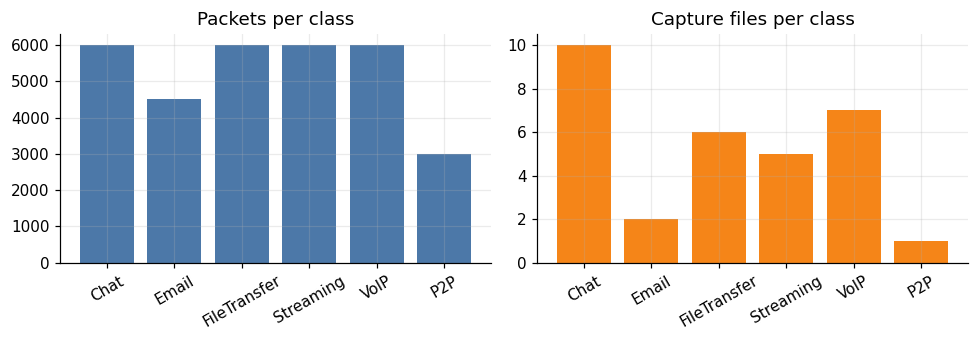

In [ ]:
SERVICES = ['Chat', 'Email', 'FileTransfer', 'Streaming', 'VoIP', 'P2P']

def find_zips():
    if CFG['zip_paths']: return list(CFG['zip_paths'])
    zs = [str(p) for p in Path(CFG['search_root']).rglob('*.zip') if 'pcap' in p.name.lower()]
    return sorted(set(zs))

def scan_archives(zips, kinds):
    parts, skipped = [], []
    for zp in zips:
        kind = archive_kind(zp)
        if kind not in kinds: continue
        for m in list_members(zp):
            svc = service_of(m)
            if svc is None: skipped.append(os.path.basename(m)); continue
            t0 = time.time()
            try:
                items, seen = read_member(zp, m, seed=len(parts))
            except Exception as e:
                print('  failed:', m, e); continue
            if not items: print('  no usable packets:', m); continue
            parts.append(dict(kind=kind, member=os.path.basename(m), svc=svc, items=items, seen=seen))
            print(f'  [{kind:6s}] {os.path.basename(m):34s} -> {svc:12s} kept={len(items):5d} seen={seen:6d} ({time.time()-t0:.1f}s)')
    return parts, skipped

def assemble(parts):
    Xs, ys, mems, fids, segs, plens, vpns, names = [], [], [], [], [], [], [], []
    for mid, p in enumerate(parts):
        n = len(p['items'])
        Xs.append(np.stack([it[0] for it in p['items']]))
        plens.append(np.array([it[1] for it in p['items']], dtype=np.int32))
        fids.append(np.array([it[2] for it in p['items']], dtype=np.int64))
        segs.append(np.array([it[3] for it in p['items']], dtype=np.int64))
        ys.append(np.full(n, SERVICES.index(p['svc']), dtype=np.int64))
        mems.append(np.full(n, mid, dtype=np.int64))
        vpns.append(np.full(n, int(p['kind'] == 'vpn'), dtype=np.int8))
        names.append(f"{p['kind']}:{p['member']}")
    return (np.concatenate(Xs), np.concatenate(ys), np.concatenate(mems), np.concatenate(fids),
            np.concatenate(segs), np.concatenate(plens), np.concatenate(vpns), names)

cache = f"/content/iscx_cache_{CFG['seg_len']}_{CFG['per_member_cap']}_{CFG['scan_limit']}_{CFG['archive_scope']}.npz"
if os.path.exists(cache):
    z = np.load(cache, allow_pickle=True)
    X, y, mem, fid, seg, plen, vpn = [z[k] for k in ('X', 'y', 'mem', 'fid', 'seg', 'plen', 'vpn')]
    mem_names = list(z['mem_names']); scope_used = str(z['scope_used'])
    print('Loaded cached dataset:', cache)
else:
    zips = find_zips()
    print('Archives found:'); [print('  ', z_, archive_kind(z_)) for z_ in zips]
    if not zips: raise FileNotFoundError('No *pcap*.zip archives found under ' + CFG['search_root'])
    scope = CFG['archive_scope']
    kinds = {'vpn': {'vpn'}, 'nonvpn': {'nonvpn'}, 'both': {'vpn', 'nonvpn'}, 'auto': {'vpn'}}[scope]
    parts, skipped = scan_archives(zips, kinds); scope_used = ','.join(sorted(kinds))
    if scope == 'auto' and len({p['svc'] for p in parts}) < 5:
        print('\n*** Fewer than 5 service classes in the VPN archives -> also adding NonVPN archives. '
              'State this in the paper (service classification over VPN and non-VPN captures). ***\n')
        more, sk2 = scan_archives(zips, {'nonvpn'}); parts += more; skipped += sk2; scope_used = 'vpn,nonvpn'
    if not parts: raise RuntimeError('No usable captures parsed. Check that 7z works and file names map to services (see service_of).')
    X, y, mem, fid, seg, plen, vpn, mem_names = assemble(parts)
    np.savez_compressed(cache, X=X, y=y, mem=mem, fid=fid, seg=seg, plen=plen, vpn=vpn,
                        mem_names=np.array(mem_names, dtype=object), scope_used=scope_used)
    print('Skipped (unmapped service) captures:', len(skipped), skipped[:12])

# drop tiny classes, cap per class, re-index
rng0 = np.random.RandomState(0)
keep = np.zeros(len(y), bool)
for c in np.unique(y):
    idc = np.where(y == c)[0]
    if len(idc) < CFG['min_class_pkts']:
        print(f'Dropping class {SERVICES[c]} ({len(idc)} packets < {CFG["min_class_pkts"]})'); continue
    if len(idc) > CFG['per_class_cap']: idc = rng0.choice(idc, CFG['per_class_cap'], replace=False)
    keep[idc] = True
X, y, mem, fid, seg, plen, vpn = X[keep], y[keep], mem[keep], fid[keep], seg[keep], plen[keep], vpn[keep]
present = sorted(np.unique(y)); remap = {c: i for i, c in enumerate(present)}
y = np.array([remap[c] for c in y]); CLASS_NAMES = [SERVICES[c] for c in present]; NC = len(CLASS_NAMES)
grp_key = (mem.astype(np.int64) << 40) | (fid.astype(np.int64) << 14) | np.minimum(seg, 16383)
_, grp = np.unique(grp_key, return_inverse=True)
N = len(y); NTOK = math.ceil(CFG['pkt_len'] / CFG['patch'])
print(f'\nDataset: {X.shape}, classes={CLASS_NAMES}, captures={len(np.unique(mem))}, flow-segment groups={grp.max()+1}')

ds_rows = []
for c in range(NC):
    m = y == c
    ds_rows.append(dict(cls=CLASS_NAMES[c], packets=int(m.sum()), captures=len(np.unique(mem[m])),
                        flow_segments=len(np.unique(grp[m])), mean_pkt_len=float(plen[m].mean()),
                        pct_vpn_captures=100 * float(vpn[m].mean())))
ds_df = save_table(pd.DataFrame(ds_rows), 'table0_dataset')
fig, ax = plt.subplots(1, 2, figsize=(9, 3.2))
ax[0].bar(ds_df.cls, ds_df.packets, color='#4c78a8'); ax[0].set_title('Packets per class'); ax[0].tick_params(axis='x', rotation=30)
ax[1].bar(ds_df.cls, ds_df.captures, color='#f58518'); ax[1].set_title('Capture files per class'); ax[1].tick_params(axis='x', rotation=30)
savefig('fig01_dataset')

## 3. Three evaluation protocols (leakage-aware splits)

| Protocol | Unit that is never shared between train and test |
|---|---|
| `packet` | nothing — random packet split (what many papers do; leaks neighbouring packets) |
| `segment` | **flow segment** (≤ `seg_len` consecutive packets of one 5-tuple) — the main protocol of this notebook |
| `capture` | whole **capture files**; only classes with ≥ 2 captures can be evaluated |

All use 70/10/20 where possible and are stratified per class.

In [ ]:
def assign_groups(idx, gids, fracs, rng, ensure=(2, 1)):
    ug, inv = np.unique(gids, return_inverse=True)
    sizes = np.bincount(inv); tot = sizes.sum(); cum = 0
    assign = np.zeros(len(ug), int)
    for gi in rng.permutation(len(ug)):
        f = cum / tot
        assign[gi] = 0 if f < fracs[0] else (1 if f < fracs[0] + fracs[1] else 2)
        cum += sizes[gi]
    if len(ug) >= 3:
        for a in ensure:
            if not (assign == a).any():
                cand = np.where(assign == 0)[0]
                if len(cand): assign[cand[np.argmin(sizes[cand])]] = a
    per = assign[inv]
    return idx[per == 0], idx[per == 1], idx[per == 2]

def make_split(protocol, seed, keep_classes=None):
    rng = np.random.RandomState(1000 + seed)
    classes = range(NC) if keep_classes is None else keep_classes
    tr, va, te = [], [], []
    for c in classes:
        idc = np.where(y == c)[0]
        if protocol == 'packet':
            idc = rng.permutation(idc); n = len(idc); a, b = int(.7 * n), int(.8 * n)
            tr.append(idc[:a]); va.append(idc[a:b]); te.append(idc[b:])
        elif protocol == 'segment':
            a, b, t = assign_groups(idc, grp[idc], (.7, .1, .2), rng); tr.append(a); va.append(b); te.append(t)
        elif protocol == 'capture':
            ms = rng.permutation(np.unique(mem[idc]))
            if len(ms) < 2: continue
            nte = max(1, int(round(.2 * len(ms)))); te_m, rest = ms[:nte], ms[nte:]
            te.append(idc[np.isin(mem[idc], te_m)])
            idr = idc[np.isin(mem[idc], rest)]
            a, b, _ = assign_groups(idr, grp[idr], (.875, .125, 0.), rng, ensure=(1,)); tr.append(a); va.append(b)
        else:
            raise ValueError(protocol)
    cat = lambda L: np.concatenate(L) if L else np.array([], dtype=int)
    return cat(tr), cat(va), cat(te)

def overlap_report(sp, name):
    tr, va, te = sp
    return dict(protocol=name, train=len(tr), val=len(va), test=len(te),
                shared_flow_segments=len(set(grp[tr]) & set(grp[te])),
                shared_captures=len(set(mem[tr]) & set(mem[te])))

rep = pd.DataFrame([overlap_report(make_split(p, 0), p) for p in ('packet', 'segment', 'capture')])
print('Sanity check: groups shared between train and test (must be 0 for the protocol unit):')
display(rep)
ELIG = [c for c in range(NC) if len(np.unique(mem[y == c])) >= 2]
print('Classes with >= 2 capture files (eligible for the capture protocol):', [CLASS_NAMES[c] for c in ELIG])

Sanity check: groups shared between train and test (must be 0 for the protocol unit):


,protocol,train,val,test,shared_flow_segments,shared_captures
0,packet,22064,3152,6304,2424,31
1,segment,22084,3146,6290,0,31
2,capture,18522,2621,7377,0,0


Classes with >= 2 capture files (eligible for the capture protocol): ['Chat', 'Email', 'FileTransfer', 'Streaming', 'VoIP']


## 4. Models

* **UTFormer** — pre-LN Transformer with a class token; **DPD sits between MHSA and FFN of the first block**, keeps the class token plus the Top-⌈γ·n⌉ content tokens (at least 4), and every later layer only sees the kept tokens.
* **Scoring rules** (Novelty 1): `head_mean` (paper), `head_max`, `col_mean` (attention received from all tokens), `value_norm` (class-token attention × ‖value‖), `learned_gate` (linear gate, trained through a sigmoid re-weighting of kept tokens), `random`, `none`.
* Baselines: Random Forest (statistics + first 64 bytes) and a small 1D-CNN.

In [ ]:
def token_scores(method, a, v):
    # a: (B,H,T,T) attention probs (row = query, token 0 = CLS); v: (B,H,T,dh). Returns (B,T-1) scores of content tokens.
    if method == 'head_mean':  return a[:, :, 0, 1:].mean(1)
    if method == 'head_max':   return a[:, :, 0, 1:].max(1).values
    if method == 'col_mean':   return a[:, :, :, 1:].mean((1, 2))
    if method == 'value_norm': return (a[:, :, 0, 1:] * v[:, :, 1:].norm(dim=-1)).mean(1)
    raise ValueError(method)

class MHSA(nn.Module):
    def __init__(s, dim, heads):
        super().__init__(); s.h = heads; s.dh = dim // heads
        s.qkv = nn.Linear(dim, 3 * dim); s.o = nn.Linear(dim, dim)
    def forward(s, x):
        B, T, D = x.shape
        q, k, v = s.qkv(x).view(B, T, 3, s.h, s.dh).permute(2, 0, 3, 1, 4)
        a = torch.softmax((q @ k.transpose(-1, -2)) / math.sqrt(s.dh), dim=-1)
        out = (a @ v).transpose(1, 2).reshape(B, T, D)
        return s.o(out), a, v

class Block(nn.Module):
    def __init__(s, dim, heads, ffn, drop):
        super().__init__()
        s.ln1 = nn.LayerNorm(dim); s.attn = MHSA(dim, heads); s.ln2 = nn.LayerNorm(dim)
        s.f1 = nn.Linear(dim, ffn); s.f2 = nn.Linear(ffn, dim); s.drop = nn.Dropout(drop)
    def attn_part(s, x):
        h, a, v = s.attn(s.ln1(x)); return x + s.drop(h), a, v
    def ffn_part(s, x):
        return x + s.drop(s.f2(F.gelu(s.f1(s.ln2(x)))))

class UTFormer(nn.Module):
    def __init__(s, n_classes, dim=64, heads=4, layers=2, ffn=128, gamma=1.0, scoring='head_mean',
                 patch=16, pkt_len=1500, min_keep=4, drop=0.1):
        super().__init__()
        s.patch = patch; s.n_tok = math.ceil(pkt_len / patch); s.pad = s.n_tok * patch - pkt_len
        s.gamma, s.scoring, s.dim = gamma, scoring, dim
        s.embed = nn.Linear(patch, dim)
        s.cls = nn.Parameter(torch.zeros(1, 1, dim))
        s.pos = nn.Parameter(torch.randn(1, s.n_tok + 1, dim) * 0.02)
        s.blocks = nn.ModuleList([Block(dim, heads, ffn, drop) for _ in range(layers)])
        s.gate = nn.Linear(dim, 1) if scoring == 'learned_gate' else None
        s.norm = nn.LayerNorm(dim); s.head = nn.Linear(dim, n_classes)
        s.keep = s.n_tok if (gamma >= 1 or scoring == 'none') else min(s.n_tok, max(min_keep, math.ceil(gamma * s.n_tok)))
    def to_tokens(s, x):
        if s.pad: x = F.pad(x, (0, s.pad))
        return x.reshape(x.shape[0], s.n_tok, s.patch)
    def _score(s, z, a, v):
        if s.scoring == 'random': return torch.rand(z.shape[0], s.n_tok, device=z.device)
        if s.scoring == 'learned_gate': return s.gate(z[:, 1:]).squeeze(-1).float()
        return token_scores(s.scoring, a, v).float()
    def forward(s, x, return_info=False):
        t = s.embed(s.to_tokens(x))
        z = torch.cat([s.cls.expand(t.shape[0], -1, -1), t], 1) + s.pos
        info = {}
        for i, blk in enumerate(s.blocks):
            z, a, v = blk.attn_part(z)
            if i == 0:
                if return_info: info['attn0'] = a; info['v0'] = v
                if s.keep < s.n_tok:
                    sc = s._score(z, a, v)
                    idx = sc.topk(s.keep, dim=1).indices.sort(dim=1).values
                    kept = torch.gather(z[:, 1:], 1, idx.unsqueeze(-1).expand(-1, -1, z.shape[-1]))
                    if s.scoring == 'learned_gate':
                        kept = kept * torch.sigmoid(torch.gather(sc, 1, idx)).unsqueeze(-1).to(kept.dtype)
                    z = torch.cat([z[:, :1], kept], 1); info['keep_idx'] = idx
            z = blk.ffn_part(z)
        out = s.head(s.norm(z[:, 0]))
        return (out, info) if return_info else out

class SmallCNN(nn.Module):
    def __init__(s, n_classes, L=1500):
        super().__init__()
        s.net = nn.Sequential(nn.Conv1d(1, 32, 7, stride=2, padding=3), nn.BatchNorm1d(32), nn.ReLU(), nn.MaxPool1d(2),
                              nn.Conv1d(32, 64, 5, padding=2), nn.BatchNorm1d(64), nn.ReLU(), nn.MaxPool1d(2),
                              nn.Conv1d(64, 64, 3, padding=1), nn.BatchNorm1d(64), nn.ReLU(), nn.AdaptiveAvgPool1d(1))
        s.fc = nn.Linear(64, n_classes)
    def forward(s, x): return s.fc(s.net(x.unsqueeze(1)).flatten(1))

def make_model(kind, kw):
    if kind == 'cnn': return SmallCNN(NC)
    return UTFormer(NC, dim=CFG['dim'], drop=CFG['drop'], pkt_len=CFG['pkt_len'], patch=CFG['patch'], **kw)

def flops_paper(Nh, Nl, d, g, Nt, l, extra_gamma=True):
    CA = 6 * Nh * Nt * l ** 2 + 2 * Nh * Nt ** 2 * l
    CAg = 6 * Nh * g * Nt * l ** 2 + 2 * Nh * (g * Nt) ** 2 * l
    CF = 4 * l * d * g * Nt
    body = (Nl - 1) * CAg + Nl * CF
    return CA + (g if extra_gamma else 1.0) * body

X_dev = torch.from_numpy(X).to(DEVICE)          # uint8, stays on the GPU
y_dev = torch.from_numpy(y).to(DEVICE)
print('Data on device:', tuple(X_dev.shape), X_dev.dtype)

Data on device: (31520, 1500) torch.uint8


## 5. Training / evaluation utilities and efficiency measurements

In [ ]:
def metrics(y_true, y_pred):
    labels = np.unique(y_true)
    p, r, f, _ = precision_recall_fscore_support(y_true, y_pred, labels=labels, average='macro', zero_division=0)
    return dict(acc=accuracy_score(y_true, y_pred), prec=p, rec=r, f1=f)

@torch.no_grad()
def predict_logits(model, Xd, idx_t, bs=1024):
    if len(idx_t) == 0: return torch.zeros((0, NC), device=DEVICE)
    model.eval(); outs = []
    for i in range(0, len(idx_t), bs):
        xb = Xd[idx_t[i:i + bs]].float() / 256
        with torch.autocast(device_type=DEVICE.type, dtype=torch.float16, enabled=USE_AMP):
            outs.append(model(xb).float())
    return torch.cat(outs)

def run_nn(model, Xd, split, epochs, seed, lr=None, bs=None, track=False):
    lr = lr or CFG['lr']; bs = bs or CFG['batch']
    tr, va, te = [torch.as_tensor(s, device=DEVICE) for s in split]
    model.to(DEVICE); opt = torch.optim.Adam(model.parameters(), lr=lr)
    scaler = torch.cuda.amp.GradScaler(enabled=USE_AMP)
    g = torch.Generator().manual_seed(seed)
    best, best_state, hist = -1.0, None, []
    for ep in range(epochs):
        model.train(); perm = torch.randperm(len(tr), generator=g).to(DEVICE); tot = 0.0; nb = 0
        for i in range(0, len(tr), bs):
            bi = tr[perm[i:i + bs]]
            xb = Xd[bi].float() / 256; yb = y_dev[bi]
            with torch.autocast(device_type=DEVICE.type, dtype=torch.float16, enabled=USE_AMP):
                loss = F.cross_entropy(model(xb).float(), yb)
            opt.zero_grad(set_to_none=True); scaler.scale(loss).backward(); scaler.step(opt); scaler.update()
            tot += loss.item(); nb += 1
        if len(va) == 0: vf = float(ep)          # no validation data: keep the last epoch
        else:
            vp = predict_logits(model, Xd, va).argmax(1).cpu().numpy()
            vf = metrics(y[va.cpu().numpy()], vp)['f1']
        hist.append(dict(epoch=ep + 1, train_loss=tot / max(nb, 1), val_f1=vf))
        if vf > best: best = vf; best_state = {k: v.detach().clone() for k, v in model.state_dict().items()}
    model.load_state_dict(best_state)
    pred = predict_logits(model, Xd, te).argmax(1).cpu().numpy(); yt = y[te.cpu().numpy()]
    return dict(**metrics(yt, pred), val_f1=best, pred=pred, y_true=yt, hist=hist, model=model)

def rf_features(Xu8, pl):
    z = Xu8.astype(np.float32) / 256; nz = (Xu8 != 0)
    st = np.column_stack([z.mean(1), z.std(1), nz.mean(1), pl / CFG['pkt_len'], nz[:, :64].mean(1),
                          nz[:, 64:256].mean(1), nz[:, 256:768].mean(1), nz[:, 768:].mean(1)])
    return np.hstack([st, z[:, :64]])

def run_rf(split, seed):
    tr, va, te = split
    rf = RandomForestClassifier(n_estimators=200, n_jobs=-1, random_state=seed, class_weight='balanced_subsample')
    rf.fit(rf_features(X[tr], plen[tr]), y[tr])
    pred = rf.predict(rf_features(X[te], plen[te]))
    return dict(**metrics(y[te], pred), val_f1=float('nan'), pred=pred, y_true=y[te], hist=[], model=rf)

def measured_flops(model):
    try:
        from torch.utils.flop_counter import FlopCounterMode
        model.eval(); x = X_dev[:1].float() / 256
        with torch.no_grad(), FlopCounterMode(display=False) as fc: model(x)
        return float(fc.get_total_flops())
    except Exception as e:
        return float('nan')

@torch.no_grad()
def measure_ips(model, bs=None, iters=None):
    bs = bs or (512 if DEVICE.type == 'cuda' else 128); iters = iters or (15 if DEVICE.type == 'cuda' else 4)
    model.eval(); x = X_dev[:bs].float() / 256
    if len(x) < bs: x = x.repeat(math.ceil(bs / len(x)), 1)[:bs]
    for _ in range(3): model(x)
    base = 0.0
    if DEVICE.type == 'cuda':
        torch.cuda.synchronize(); torch.cuda.reset_peak_memory_stats(); base = torch.cuda.memory_allocated()
    t = time.time()
    for _ in range(iters): model(x)
    if DEVICE.type == 'cuda': torch.cuda.synchronize()
    dt = time.time() - t
    mem_mb = (torch.cuda.max_memory_allocated() - base) / 1e6 if DEVICE.type == 'cuda' else float('nan')
    return bs * iters / dt, mem_mb

def n_params(model): return sum(p.numel() for p in model.parameters())
print('Utilities ready.')

Utilities ready.


## 5b. Differentiable Architecture Search (DAS) — Algorithm 1 of the paper

The architecture vector is **P = {N_h, N_l, d, γ}** (heads, layers, FFN hidden size, byte-keeping rate). One search iteration (Algorithm 1):

1. decode the current parameters to a concrete architecture (Eq. 6: integers by rounding), **train it** for a few epochs and measure the validation loss `L_v`;
2. compute the cost `C(P)` with the FLOP model of Eqs. 8–11 and the **unified loss** `L = α‖L_v‖ + β‖C(P)‖` (Eq. 7), both normalised to (0, 1];
3. get the gradient with respect to the **normalised parameters** `p_R = p / Max(p)` (Eq. 4), take an SGD step (Eq. 5), clip to the valid range;
4. stop when the decoded architecture is stable or the iteration budget is spent (paper: 15 iterations, 4 epochs each, γ ≥ 0.05, Max = 12 heads / 12 layers / d = 1024).

**What the paper leaves open and what this notebook does (disclose in the paper):**
* `∂L_v/∂p` is not defined for integer parameters. We estimate it with **SPSA** (two extra trainings with a random ± perturbation of all four parameters, common random numbers), a standard stochastic gradient estimate; the cost gradient is computed numerically from Eqs. 8–11.
* The paper's `lr = 0.005` does not move the parameters (this is exactly what our first attempt showed). We use **normalised-step SGD**: the step is `lr_t · g / max|g|`, so `lr` is the largest change in normalised units per iteration, annealed by `lr_decay`.
* Heads are snapped to a divisor of the embedding size; the search runs on a training subset (`das_train_n`) for speed; `Ω_Loss` (historical mean loss) and `Δ_Loss` are logged as in Algorithm 1.
* The reference cost for normalising `C(P)` is the maximum configuration (12 heads, 12 layers, d = 1024, γ = 1) at our embedding size.

In [ ]:
# ---- DAS core (numpy only): Eqs. 4-11 and Algorithm 1 --------------------------------
DAS_MAX = dict(Nh=12, Nl=12, d=1024); DAS_MIN_D = 16
DAS_LO = np.array([1 / 12, 1 / 12, DAS_MIN_D / 1024, 0.05])      # lower bounds in normalised space
LV_MAX = 2.0                                                      # range of the validation loss, (0, 2]

def valid_heads(dim): return [h for h in range(1, DAS_MAX['Nh'] + 1) if dim % h == 0]
def snap_heads(h, dim): return min(valid_heads(dim), key=lambda v: (abs(v - h), v))

def das_normalize(P):                                             # Eq. 4: p_R = p / Max(p)
    return np.array([P['Nh'] / DAS_MAX['Nh'], P['Nl'] / DAS_MAX['Nl'], P['d'] / DAS_MAX['d'], P['gamma']])

def das_decode(theta, dim):                                       # Eq. 6: back to the native domains
    th = np.clip(np.asarray(theta, float), DAS_LO, 1.0)
    return dict(Nh=snap_heads(int(round(th[0] * DAS_MAX['Nh'])), dim), Nl=max(1, int(round(th[1] * DAS_MAX['Nl']))),
                d=max(DAS_MIN_D, int(round(th[2] * DAS_MAX['d']))), gamma=round(float(th[3]), 3))

def das_cost(theta, dim, ntok, extra):                            # C(P), Eqs. 8-11
    th = np.clip(np.asarray(theta, float), DAS_LO, 1.0)
    return flops_paper(th[0] * DAS_MAX['Nh'], th[1] * DAS_MAX['Nl'], th[2] * DAS_MAX['d'], th[3], ntok, dim, extra)

def das_cost_grad(theta, dim, ntok, extra, cref, h=1e-3):
    g = np.zeros(4)
    for i in range(4):
        e = np.zeros(4); e[i] = h
        g[i] = (das_cost(theta + e, dim, ntok, extra) - das_cost(theta - e, dim, ntok, extra)) / (2 * h * cref)
    return g

def das_unified(lv, cnorm, alpha, beta):                          # Eq. 7 (both terms normalised)
    return alpha * abs(lv / LV_MAX) + beta * abs(cnorm)

def das_search(eval_fn, alpha, beta, iters, theta0, dim, ntok, lr=0.15, lr_decay=0.85, c=0.12, patience=3,
               extra=True, seed=0, verbose=True):
    rng = np.random.RandomState(seed); theta = np.clip(np.array(theta0, float), DAS_LO, 1.0)
    cref = das_cost(np.ones(4), dim, ntok, extra); rows, losses, same = [], [], 0
    for it in range(iters):
        P = das_decode(theta, dim)
        lv = float(eval_fn(P, it))                                # train Model(P), validate (lines 2-3)
        cn = das_cost(das_normalize(P), dim, ntok, extra) / cref
        L = das_unified(lv, cn, alpha, beta)                      # line 4
        omega = float(np.mean(losses)) if losses else L; losses.append(L)   # line 5: baseline Ω and Δloss
        delta = rng.choice([-1.0, 1.0], 4)                        # SPSA perturbation for dL_v/dp
        tp, tm = np.clip(theta + c * delta, DAS_LO, 1.0), np.clip(theta - c * delta, DAS_LO, 1.0)
        Pp, Pm = das_decode(tp, dim), das_decode(tm, dim); gL = np.zeros(4)
        if Pp != Pm:
            dl = (float(eval_fn(Pp, it)) - float(eval_fn(Pm, it))); span = tp - tm
            gL = np.where(np.abs(span) > 1e-9, dl / np.where(np.abs(span) > 1e-9, span, 1.0), 0.0)
        g = alpha / LV_MAX * gL + beta * das_cost_grad(theta, dim, ntok, extra, cref)   # line 6
        step = lr * (lr_decay ** it) * g / (np.max(np.abs(g)) + 1e-12)
        theta = np.clip(theta - step, DAS_LO, 1.0)                # line 7-8 (Eq. 5)
        Pn = das_decode(theta, dim); same = same + 1 if Pn == P else 0
        rows.append(dict(iteration=it + 1, Nh=P['Nh'], Nl=P['Nl'], d=P['d'], gamma=P['gamma'], val_loss=lv, cost_norm=cn,
                         unified_loss=L, omega=omega, delta_loss=L - omega, th_Nh=theta[0], th_Nl=theta[1], th_d=theta[2], th_gamma=theta[3]))
        if verbose: print(f'  DAS it {it+1:2d}: P={P} Lv={lv:.4f} C={cn:.4f} L={L:.4f} -> next {Pn}')
        if same >= patience:
            if verbose: print(f'  DAS stable for {patience} iterations -> stop');
            break
    hist = pd.DataFrame(rows)
    best = hist.loc[hist.unified_loss.idxmin()]
    return hist, das_decode(theta, dim), dict(Nh=int(best.Nh), Nl=int(best.Nl), d=int(best.d), gamma=float(best.gamma))
print('DAS core ready; valid head counts for dim', CFG['dim'], ':', valid_heads(CFG['dim']))

DAS core ready; valid head counts for dim 64 : [1, 2, 4, 8]


In [ ]:
# ---- DAS evaluation function (trains Model(P) on a subset) and the search run ----------
sp0 = make_split('segment', 0); rs_ = np.random.RandomState(7)
DAS_TR = rs_.choice(sp0[0], min(CFG['das_train_n'], len(sp0[0])), replace=False)
_va_pool = sp0[1] if len(sp0[1]) > 0 else sp0[0]
DAS_VA = rs_.choice(_va_pool, min(CFG['das_val_n'], len(_va_pool)), replace=False)
DAS_TR_T, DAS_VA_T = torch.as_tensor(DAS_TR, device=DEVICE), torch.as_tensor(DAS_VA, device=DEVICE)
_das_cache = {}

def das_eval_fn(P, seed):
    key = (P['Nh'], P['Nl'], P['d'], P['gamma'], seed)
    if key in _das_cache: return _das_cache[key]
    seed_all(1000 + seed)
    m = make_model('ut', dict(layers=P['Nl'], heads=P['Nh'], ffn=P['d'], gamma=P['gamma'], scoring='head_mean')).to(DEVICE)
    opt = torch.optim.Adam(m.parameters(), lr=CFG['lr']); scaler = torch.cuda.amp.GradScaler(enabled=USE_AMP)
    g = torch.Generator().manual_seed(seed)
    for ep in range(CFG['das_epochs']):
        m.train(); perm = torch.randperm(len(DAS_TR_T), generator=g).to(DEVICE)
        for i in range(0, len(perm), CFG['batch']):
            bi = DAS_TR_T[perm[i:i + CFG['batch']]]
            with torch.autocast(device_type=DEVICE.type, dtype=torch.float16, enabled=USE_AMP):
                loss = F.cross_entropy(m(X_dev[bi].float() / 256).float(), y_dev[bi])
            opt.zero_grad(set_to_none=True); scaler.scale(loss).backward(); scaler.step(opt); scaler.update()
    lv = F.cross_entropy(predict_logits(m, X_dev, DAS_VA_T), y_dev[DAS_VA_T]).item()
    if not np.isfinite(lv): lv = LV_MAX
    del m, opt;
    if DEVICE.type == 'cuda': torch.cuda.empty_cache()
    _das_cache[key] = lv
    return lv

def run_das(alpha, beta, iters, tag=''):
    t0 = time.time(); print(f'DAS search {tag} alpha={alpha} beta={beta} iters<={iters}')
    out = das_search(das_eval_fn, alpha, beta, iters, CFG['das_init'], CFG['dim'], NTOK, lr=CFG['das_lr'], lr_decay=CFG['das_lr_decay'],
                     c=CFG['das_c'], patience=CFG['das_patience'], extra=CFG['das_cost_extra_gamma'], seed=0)
    print(f'  done in {time.time()-t0:.0f}s -> final P = {out[1]}'); return out

das_hist, DAS_P, DAS_P_BEST = run_das(CFG['das_alpha'], CFG['das_beta'], CFG['das_iters'], 'main')
save_table(das_hist.round(4), 'table9_das_search_log')
print('Final architecture (paper protocol: last iterate):', DAS_P, '| lowest-unified-loss iterate:', DAS_P_BEST)

DAS search main alpha=0.5 beta=1.5 iters<=15
  DAS it  1: P={'Nh': 4, 'Nl': 4, 'd': 358, 'gamma': 0.5} Lv=0.3990 C=0.0392 L=0.1585 -> next {'Nh': 2, 'Nl': 4, 'd': 386, 'gamma': 0.35}
  DAS it  2: P={'Nh': 2, 'Nl': 4, 'd': 386, 'gamma': 0.35} Lv=0.4526 C=0.0170 L=0.1386 -> next {'Nh': 2, 'Nl': 5, 'd': 517, 'gamma': 0.404}
  DAS it  3: P={'Nh': 2, 'Nl': 5, 'd': 517, 'gamma': 0.404} Lv=0.4137 C=0.0261 L=0.1426 -> next {'Nh': 1, 'Nl': 4, 'd': 467, 'gamma': 0.317}
  DAS it  4: P={'Nh': 1, 'Nl': 4, 'd': 467, 'gamma': 0.317} Lv=0.9189 C=0.0111 L=0.2463 -> next {'Nh': 2, 'Nl': 3, 'd': 531, 'gamma': 0.373}
  DAS it  5: P={'Nh': 2, 'Nl': 3, 'd': 531, 'gamma': 0.373} Lv=0.8076 C=0.0174 L=0.2279 -> next {'Nh': 2, 'Nl': 2, 'd': 457, 'gamma': 0.437}
  DAS it  6: P={'Nh': 2, 'Nl': 2, 'd': 457, 'gamma': 0.437} Lv=0.3930 C=0.0154 L=0.1213 -> next {'Nh': 2, 'Nl': 2, 'd': 402, 'gamma': 0.472}
  DAS it  7: P={'Nh': 2, 'Nl': 2, 'd': 402, 'gamma': 0.472} Lv=0.3817 C=0.0157 L=0.1190 -> next {'Nh': 2, 'Nl': 1

,iteration,Nh,Nl,d,gamma,val_loss,cost_norm,unified_loss,omega,delta_loss,th_Nh,th_Nl,th_d,th_gamma
0,1,4,4,358,0.500,0.3990,0.0392,0.1585,0.1585,0.0000,0.1986,0.3234,0.3774,0.3500
1,2,2,4,386,0.350,0.4526,0.0170,0.1386,0.1585,-0.0199,0.2202,0.4205,0.5049,0.4044
2,3,2,5,517,0.404,0.4137,0.0261,0.1426,0.1486,-0.0060,0.1118,0.3463,0.4565,0.3174
3,4,1,4,467,0.317,0.9189,0.0111,0.2463,0.1466,0.0998,0.2039,0.2765,0.5190,0.3730
4,5,2,3,531,0.373,0.8076,0.0174,0.2279,0.1715,0.0564,0.1256,0.2010,0.4467,0.4372
5,6,2,2,457,0.437,0.3930,0.0154,0.1213,0.1828,-0.0615,0.1732,0.1344,0.3922,0.4720
6,7,2,2,402,0.472,0.3817,0.0157,0.1190,0.1725,-0.0535,0.1566,0.0833,0.3682,0.4405
7,8,2,1,377,0.440,0.2740,0.0109,0.0849,0.1649,-0.0800,0.1085,0.0833,0.3691,0.4217
8,9,1,1,378,0.422,0.3791,0.0064,0.1044,0.1549,-0.0505,0.0833,0.0833,0.3766,0.4254
9,10,1,1,386,0.425,0.4652,0.0065,0.1260,0.1493,-0.0233,0.1072,0.0833,0.3599,0.4381


Final architecture (paper protocol: last iterate): {'Nh': 1, 'Nl': 1, 'd': 338, 'gamma': 0.422} | lowest-unified-loss iterate: {'Nh': 2, 'Nl': 1, 'd': 377, 'gamma': 0.44}


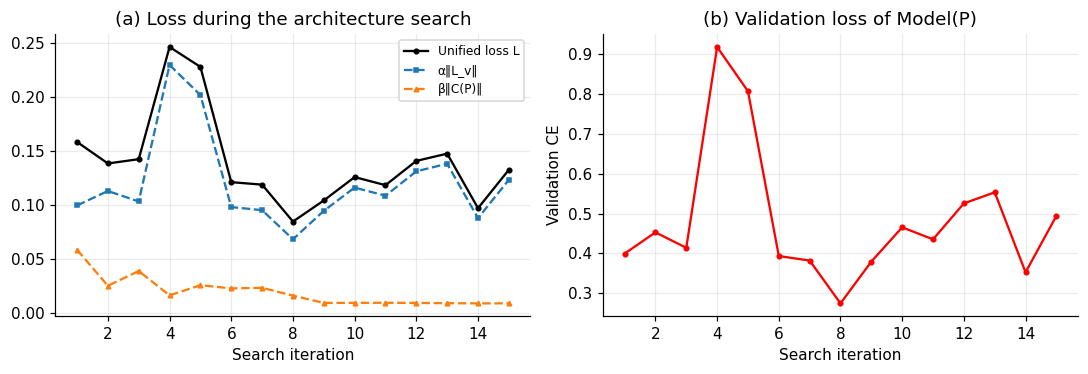

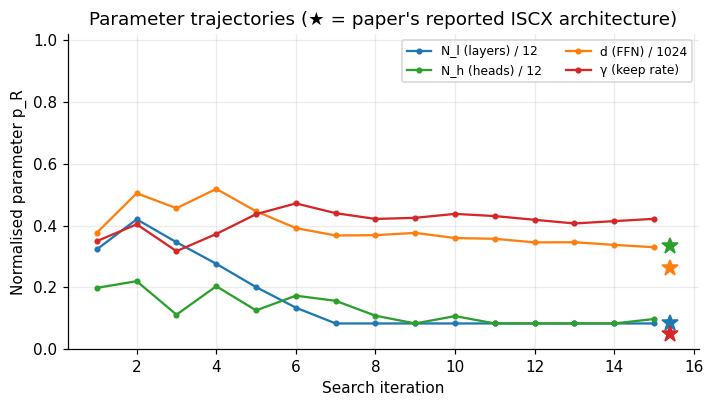

,Architecture,N_l,N_h,FFN d,γ,Kept tokens,Params,Size (KB),FLOPs (Eq.8 as printed),FLOPs/pkt (measured)
0,"DAS (this notebook, last iterate)",1,1,338,0.422,40,68312,266.844,4.913969e+06,9164288.0
1,DAS (lowest unified loss),1,2,377,0.440,42,73343,286.496,8.693444e+06,9766656.0
2,Paper-reported ISCX,1,4,268,0.050,5,59282,231.570,1.378285e+07,6028288.0


,Architecture,N_l,N_h,FFN d,γ,Kept tokens,Params,Size (KB),FLOPs (Eq.8 as printed),FLOPs/pkt (measured)
0,"DAS (this notebook, last iterate)",1,1,338,0.422,40,68312,266.844,4.913969e+06,9164288.0
1,DAS (lowest unified loss),1,2,377,0.440,42,73343,286.496,8.693444e+06,9766656.0
2,Paper-reported ISCX,1,4,268,0.050,5,59282,231.570,1.378285e+07,6028288.0


In [ ]:
# ---- DAS figures: convergence of the loss (Fig 14) and of the parameters (Fig 15) ------
its = das_hist.iteration.values
fig, ax = plt.subplots(1, 2, figsize=(10, 3.5))
ax[0].plot(its, das_hist.unified_loss, 'k-o', ms=3, label='Unified loss L')
ax[0].plot(its, CFG['das_alpha'] * das_hist.val_loss / LV_MAX, '--s', ms=3, label='α‖L_v‖')
ax[0].plot(its, CFG['das_beta'] * das_hist.cost_norm, '--^', ms=3, label='β‖C(P)‖')
ax[0].set_xlabel('Search iteration'); ax[0].set_title('(a) Loss during the architecture search'); ax[0].legend(fontsize=8)
ax[1].plot(its, das_hist.val_loss, 'r-o', ms=3); ax[1].set_xlabel('Search iteration'); ax[1].set_ylabel('Validation CE'); ax[1].set_title('(b) Validation loss of Model(P)')
savefig('fig14_das_convergence')

paper_final = dict(Nh=4 / 12, Nl=1 / 12, d=268 / 1024, gamma=0.05)
fig, ax = plt.subplots(figsize=(6.6, 3.8))
for key, lab, col in [('th_Nl', 'N_l (layers) / 12', '#1f77b4'), ('th_Nh', 'N_h (heads) / 12', '#2ca02c'), ('th_d', 'd (FFN) / 1024', '#ff7f0e'), ('th_gamma', 'γ (keep rate)', '#d62728')]:
    ax.plot(its, das_hist[key], '-o', ms=3, color=col, label=lab)
xr = its[-1] + 0.4
for (k_, col) in zip(['Nl', 'Nh', 'd', 'gamma'], ['#1f77b4', '#2ca02c', '#ff7f0e', '#d62728']):
    ax.plot([xr], [paper_final[k_]], marker='*', ms=11, color=col, ls='none')
ax.set_xlabel('Search iteration'); ax.set_ylabel('Normalised parameter p_R'); ax.set_ylim(0, 1.02)
ax.set_title('Parameter trajectories (★ = paper\'s reported ISCX architecture)'); ax.legend(fontsize=8, ncol=2)
savefig('fig15_das_parameters')

# ---- architecture comparison table (Table 10) -----------------------------------------
def arch_row(name, P):
    m = make_model('ut', dict(layers=P['Nl'], heads=P['Nh'], ffn=P['d'], gamma=P['gamma'], scoring='head_mean'))
    m.to(DEVICE); g_ = m.keep / m.n_tok
    return {'Architecture': name, 'N_l': P['Nl'], 'N_h': P['Nh'], 'FFN d': P['d'], 'γ': P['gamma'], 'Kept tokens': m.keep, 'Params': n_params(m),
            'Size (KB)': n_params(m) * 4 / 1024, 'FLOPs (Eq.8 as printed)': flops_paper(P['Nh'], P['Nl'], P['d'], g_, m.n_tok, m.dim, True),
            'FLOPs/pkt (measured)': measured_flops(m)}
ARCHS = [('DAS (this notebook, last iterate)', DAS_P), ('DAS (lowest unified loss)', DAS_P_BEST),
         ('Paper-reported ISCX', dict(Nh=4, Nl=1, d=268, gamma=0.05))]
save_table(pd.DataFrame([arch_row(n, p) for n, p in ARCHS]).round(3), 'table10_das_architectures')

DAS search coef 3:1 alpha=3 beta=1 iters<=10
  DAS it  1: P={'Nh': 4, 'Nl': 4, 'd': 358, 'gamma': 0.5} Lv=0.3990 C=0.0392 L=0.6377 -> next {'Nh': 2, 'Nl': 5, 'd': 481, 'gamma': 0.35}
  DAS it  2: P={'Nh': 2, 'Nl': 5, 'd': 481, 'gamma': 0.35} Lv=0.6733 C=0.0210 L=1.0310 -> next {'Nh': 2, 'Nl': 7, 'd': 612, 'gamma': 0.406}
  DAS it  3: P={'Nh': 2, 'Nl': 7, 'd': 612, 'gamma': 0.406} Lv=0.6155 C=0.0371 L=0.9604 -> next {'Nh': 2, 'Nl': 5, 'd': 503, 'gamma': 0.508}
  DAS it  4: P={'Nh': 2, 'Nl': 5, 'd': 503, 'gamma': 0.508} Lv=0.4198 C=0.0360 L=0.6656 -> next {'Nh': 1, 'Nl': 6, 'd': 428, 'gamma': 0.433}
  DAS it  5: P={'Nh': 1, 'Nl': 6, 'd': 428, 'gamma': 0.433} Lv=1.1115 C=0.0223 L=1.6895 -> next {'Nh': 1, 'Nl': 6, 'd': 388, 'gamma': 0.471}
  DAS it  6: P={'Nh': 1, 'Nl': 6, 'd': 388, 'gamma': 0.471} Lv=1.2335 C=0.0240 L=1.8743 -> next {'Nh': 1, 'Nl': 6, 'd': 421, 'gamma': 0.437}
  DAS it  7: P={'Nh': 1, 'Nl': 6, 'd': 421, 'gamma': 0.437} Lv=0.5789 C=0.0224 L=0.8907 -> next {'Nh': 2, 'Nl': 6

,α:β,"Architecture (N_l,N_h,d)",Size (KB),γ,FLOPs (Eq.8),Accuracy (%),Macro-F1 (%)
0,3:1,"(5,2,418)",1414.688,0.428,2.071715e+07,94.245,94.430
1,2:1,"(1,2,218)",206.375,0.430,7.880317e+06,92.766,92.708
2,1:1,"(3,2,305)",690.098,0.416,1.289122e+07,95.453,95.504
3,0.5:1,"(1,2,314)",254.750,0.259,7.416772e+06,93.736,93.904


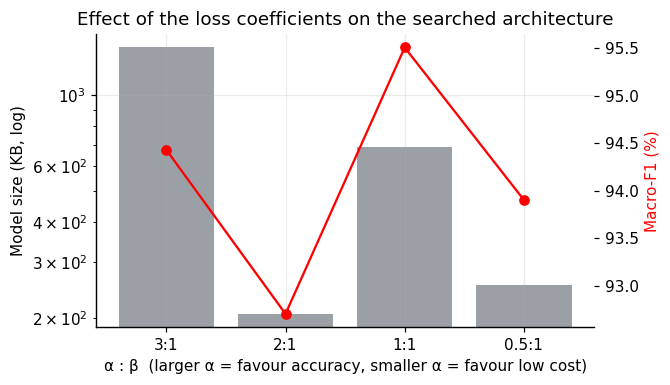

In [ ]:
# ---- Coefficient study (paper Table VII): how alpha:beta steers the search -------------
if CFG['das_coef_study']:
    rows = []
    for a_, b_ in CFG['das_coefs']:
        h_, P_, _ = run_das(a_, b_, CFG['das_iters_coef'], f'coef {a_}:{b_}')
        seed_all(0); m = make_model('ut', dict(layers=P_['Nl'], heads=P_['Nh'], ffn=P_['d'], gamma=P_['gamma'], scoring='head_mean'))
        r = run_nn(m, X_dev, sp0, CFG['sweep_epochs'], 0); g_ = m.keep / m.n_tok
        rows.append({'α:β': f'{a_}:{b_}', 'Architecture (N_l,N_h,d)': f"({P_['Nl']},{P_['Nh']},{P_['d']})", 'Size (KB)': n_params(m) * 4 / 1024,
                     'γ': P_['gamma'], 'FLOPs (Eq.8)': flops_paper(P_['Nh'], P_['Nl'], P_['d'], g_, m.n_tok, m.dim, True),
                     'Accuracy (%)': 100 * r['acc'], 'Macro-F1 (%)': 100 * r['f1']})
    t11 = save_table(pd.DataFrame(rows).round(3), 'table11_das_coefficients')
    fig, ax = plt.subplots(figsize=(6.2, 3.6)); x = np.arange(len(t11))
    ax.bar(x, t11['Size (KB)'], color='#9aa0a6'); ax.set_yscale('log'); ax.set_ylabel('Model size (KB, log)')
    ax.set_xticks(x); ax.set_xticklabels(t11['α:β']); ax.set_xlabel('α : β  (larger α = favour accuracy, smaller α = favour low cost)')
    ax2 = ax.twinx(); ax2.plot(x, t11['Macro-F1 (%)'], 'r-o'); ax2.set_ylabel('Macro-F1 (%)', color='r'); ax2.grid(False)
    ax.set_title('Effect of the loss coefficients on the searched architecture'); savefig('fig16_das_coefficients')
else:
    print('Coefficient study skipped (CFG["das_coef_study"] = False).')

## 6. Experiment A — main results, baselines and efficiency (Tables 1–2, Figs 2–4)

Protocol: **flow-segment split**, mean ± std over seeds. Paper reference for ISCX-VPN (6 classes): accuracy 94.35 %, F1 93.24 %, 156 KB, ≈241.8 kFLOPs (numbers are **not directly comparable**: different captures, packet sampling and split).

seed 0 | RF (stats + first 64 B)          acc=0.9886 F1=0.9882 (9s)
seed 0 | 1D-CNN                           acc=0.7221 F1=0.7204 (17s)
seed 0 | Transformer, no DPD (2L)         acc=0.9630 F1=0.9637 (26s)
seed 0 | UTFormer paper-cfg (1L, γ=5%)    acc=0.9688 F1=0.9684 (14s)
seed 0 | UTFormer 2L γ=50%                acc=0.9682 F1=0.9684 (20s)
seed 0 | UTFormer 2L γ=20%                acc=0.9719 F1=0.9721 (18s)
seed 0 | UTFormer 2L γ=5%                 acc=0.9757 F1=0.9757 (18s)
seed 0 | UTFormer-DAS (searched)          acc=0.9512 F1=0.9526 (11s)
seed 1 | RF (stats + first 64 B)          acc=0.9879 F1=0.9889 (11s)
seed 1 | 1D-CNN                           acc=0.7218 F1=0.7082 (15s)
seed 1 | Transformer, no DPD (2L)         acc=0.9659 F1=0.9674 (26s)
seed 1 | UTFormer paper-cfg (1L, γ=5%)    acc=0.9665 F1=0.9668 (14s)
seed 1 | UTFormer 2L γ=50%                acc=0.9662 F1=0.9688 (20s)
seed 1 | UTFormer 2L γ=20%                acc=0.9715 F1=0.9729 (19s)
seed 1 | UTFormer 2L γ=5%          

,Model,Accuracy (%),Precision (%),Recall (%),F1 (%)
0,RF (stats + first 64 B),98.80 ± 0.05,98.85 ± 0.06,98.89 ± 0.01,98.87 ± 0.04
1,1D-CNN,72.36 ± 0.28,78.40 ± 2.29,71.69 ± 1.34,71.53 ± 0.63
2,"Transformer, no DPD (2L)",96.57 ± 0.26,96.63 ± 0.32,96.77 ± 0.31,96.69 ± 0.30
3,"UTFormer paper-cfg (1L, γ=5%)",96.72 ± 0.14,96.67 ± 0.08,96.85 ± 0.10,96.76 ± 0.08
4,UTFormer 2L γ=50%,96.70 ± 0.10,96.75 ± 0.12,96.94 ± 0.07,96.83 ± 0.05
5,UTFormer 2L γ=20%,97.24 ± 0.14,97.29 ± 0.19,97.42 ± 0.15,97.35 ± 0.17
6,UTFormer 2L γ=5%,97.00 ± 0.51,97.10 ± 0.31,97.22 ± 0.47,97.15 ± 0.38
7,UTFormer-DAS (searched),94.95 ± 0.58,95.14 ± 0.67,95.23 ± 0.50,95.15 ± 0.60


,Model,Params,Size (KB),FLOPs/pkt (measured),FLOPs (Eq.8 as printed),"FLOPs (Eq.8, no extra γ)",IPS (M/s),GPU mem (MB)
0,RF (stats + first 64 B),NaN,26271.589844,NaN,NaN,NaN,0.030818,NaN
1,1D-CNN,23622.0,92.273438,12612480.0,NaN,NaN,0.060382,177.881088
2,"Transformer, no DPD (2L)",74694.0,291.773438,17265920.0,3.368960e+07,33689600.0,0.034783,335.552512
3,"UTFormer paper-cfg (1L, γ=5%)",59282.0,231.570312,6028288.0,1.378285e+07,14107648.0,0.083677,222.838784
4,UTFormer 2L γ=50%,74694.0,291.773438,10925056.0,1.818035e+07,22596096.0,0.051895,222.838784
5,UTFormer 2L γ=20%,74694.0,291.773438,7685120.0,1.443118e+07,17062400.0,0.066877,222.838784
6,UTFormer 2L γ=5%,74694.0,291.773438,6215680.0,1.380886e+07,14596608.0,0.083875,222.838784
7,UTFormer-DAS (searched),68312.0,266.843750,9164288.0,4.913969e+06,6902272.0,0.099790,136.288256


Note: measured FLOPs count matmul/conv only (torch FlopCounterMode). Eq. 8 of the paper multiplies the bracket by γ although C_Aγ and C_F already contain γ; both variants are reported.


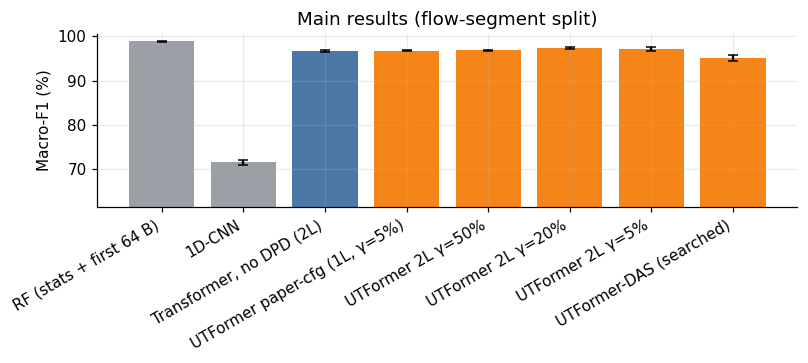

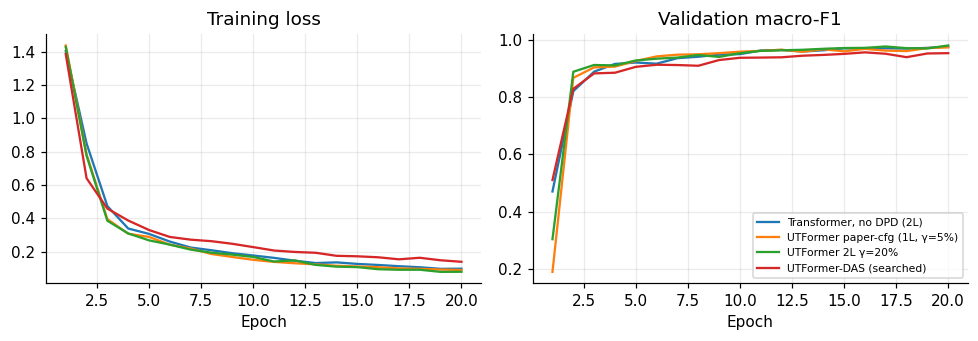

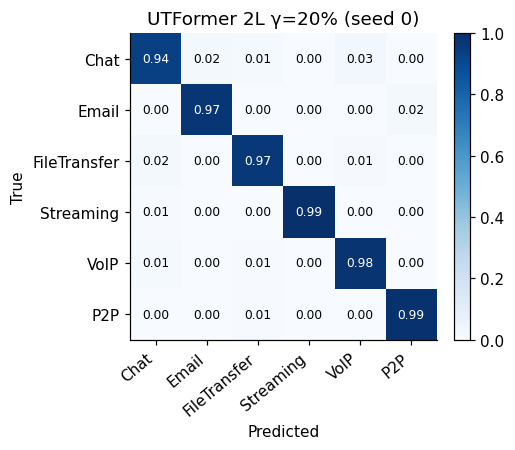

,class,precision,recall,f1,support
0,Chat,0.960481,0.936348,0.948261,1194
1,Email,0.965859,0.974444,0.970133,900
2,FileTransfer,0.978041,0.968227,0.973109,1196
3,Streaming,1.000000,0.992500,0.996236,1200
4,VoIP,0.957655,0.980000,0.968699,1200
5,P2P,0.964228,0.988333,0.976132,600


,class,precision,recall,f1,support
0,Chat,0.960481,0.936348,0.948261,1194
1,Email,0.965859,0.974444,0.970133,900
2,FileTransfer,0.978041,0.968227,0.973109,1196
3,Streaming,1.000000,0.992500,0.996236,1200
4,VoIP,0.957655,0.980000,0.968699,1200
5,P2P,0.964228,0.988333,0.976132,600


In [ ]:
UT2 = dict(layers=CFG['layers'], heads=CFG['heads'], ffn=CFG['ffn'])
MAIN_SPECS = [
    ('RF (stats + first 64 B)', 'rf', {}),
    ('1D-CNN', 'cnn', {}),
    ('Transformer, no DPD (2L)', 'ut', dict(**UT2, gamma=1.0, scoring='none')),
    ('UTFormer paper-cfg (1L, γ=5%)', 'ut', dict(layers=CFG['paper_layers'], heads=CFG['paper_heads'], ffn=CFG['paper_ffn'], gamma=CFG['paper_gamma'], scoring='head_mean')),
    ('UTFormer 2L γ=50%', 'ut', dict(**UT2, gamma=0.5, scoring='head_mean')),
    ('UTFormer 2L γ=20%', 'ut', dict(**UT2, gamma=0.2, scoring='head_mean')),
    ('UTFormer 2L γ=5%', 'ut', dict(**UT2, gamma=0.05, scoring='head_mean')),
]
NAME_BASE, NAME_DPD = 'Transformer, no DPD (2L)', 'UTFormer 2L γ=20%'
if abs(CFG['main_gamma'] - 0.2) > 1e-9:
    MAIN_SPECS[5] = (f"UTFormer 2L γ={int(CFG['main_gamma']*100)}%", 'ut', dict(**UT2, gamma=CFG['main_gamma'], scoring='head_mean'))
    NAME_DPD = MAIN_SPECS[5][0]

NAME_DAS = 'UTFormer-DAS (searched)'
MAIN_SPECS.append((NAME_DAS, 'ut', dict(layers=DAS_P['Nl'], heads=DAS_P['Nh'], ffn=DAS_P['d'], gamma=DAS_P['gamma'], scoring='head_mean')))
main_rows, MAIN = [], {}
for seed in CFG['seeds']:
    sp = make_split('segment', seed)
    for name, kind, kw in MAIN_SPECS:
        seed_all(seed); t0 = time.time()
        r = run_rf(sp, seed) if kind == 'rf' else run_nn(make_model(kind, kw), X_dev, sp, CFG['epochs'], seed)
        main_rows.append(dict(model=name, seed=seed, acc=r['acc'], prec=r['prec'], rec=r['rec'], f1=r['f1']))
        if seed == CFG['seeds'][0]: MAIN[name] = dict(r=r, split=sp, kind=kind, kw=kw)
        print(f'seed {seed} | {name:32s} acc={r["acc"]:.4f} F1={r["f1"]:.4f} ({time.time()-t0:.0f}s)')
main_df = pd.DataFrame(main_rows)
agg = main_df.groupby('model', sort=False)[['acc', 'prec', 'rec', 'f1']].agg(['mean', 'std']).fillna(0)
t1 = pd.DataFrame({'Model': agg.index})
for k, lab in [('acc', 'Accuracy'), ('prec', 'Precision'), ('rec', 'Recall'), ('f1', 'F1')]:
    t1[lab + ' (%)'] = [f'{100*agg[(k,"mean")][m]:.2f} ± {100*agg[(k,"std")][m]:.2f}' for m in agg.index]
save_table(t1, 'table1_main_results'); main_df.to_csv(f'{TAB}/table1_main_results_raw.csv', index=False)

# efficiency table (seed-0 models)
eff = []
for name, kind, kw in MAIN_SPECS:
    r = MAIN[name]['r']; m = r['model']
    if kind == 'rf':
        import pickle
        sz = len(pickle.dumps(m)) / 1024; xs = rf_features(X[:2000], plen[:2000]); t0 = time.time(); m.predict(xs)
        eff.append({'Model': name, 'Params': float('nan'), 'Size (KB)': sz, 'FLOPs/pkt (measured)': float('nan'),
                    'FLOPs (Eq.8 as printed)': float('nan'), 'FLOPs (Eq.8, no extra γ)': float('nan'),
                    'IPS (M/s)': len(xs) / (time.time() - t0) / 1e6, 'GPU mem (MB)': float('nan')})
        continue
    ips, mem_mb = measure_ips(m); pc = n_params(m); fp = fe = float('nan')
    if kind == 'ut':
        g = m.keep / m.n_tok
        fp = flops_paper(kw['heads'], kw['layers'], kw['ffn'], g, m.n_tok, m.dim, True)
        fe = flops_paper(kw['heads'], kw['layers'], kw['ffn'], g, m.n_tok, m.dim, False)
    eff.append({'Model': name, 'Params': pc, 'Size (KB)': pc * 4 / 1024, 'FLOPs/pkt (measured)': measured_flops(m),
                'FLOPs (Eq.8 as printed)': fp, 'FLOPs (Eq.8, no extra γ)': fe, 'IPS (M/s)': ips / 1e6, 'GPU mem (MB)': mem_mb})
eff_df = save_table(pd.DataFrame(eff), 'table2_efficiency')
print('Note: measured FLOPs count matmul/conv only (torch FlopCounterMode). Eq. 8 of the paper multiplies the bracket by γ although C_Aγ and C_F already contain γ; both variants are reported.')

# ---- figures
fig, ax = plt.subplots(figsize=(7.5, 3.4))
means = agg[('f1', 'mean')].values * 100; stds = agg[('f1', 'std')].values * 100
cols = ['#9aa0a6', '#9aa0a6', '#4c78a8'] + ['#f58518'] * (len(MAIN_SPECS) - 3)
ax.bar(range(len(means)), means, yerr=stds, color=cols, capsize=3)
ax.set_xticks(range(len(means))); ax.set_xticklabels(agg.index, rotation=30, ha='right'); ax.set_ylabel('Macro-F1 (%)')
ax.set_ylim(max(0, means.min() - 10), 100.5); ax.set_title('Main results (flow-segment split)')
savefig('fig02_main_f1_bars')

fig, ax = plt.subplots(1, 2, figsize=(9, 3.2))
for name in [NAME_BASE, MAIN_SPECS[3][0], NAME_DPD, NAME_DAS]:
    h = pd.DataFrame(MAIN[name]['r']['hist'])
    ax[0].plot(h.epoch, h.train_loss, label=name); ax[1].plot(h.epoch, h.val_f1, label=name)
ax[0].set_title('Training loss'); ax[1].set_title('Validation macro-F1')
for a_ in ax: a_.set_xlabel('Epoch')
ax[1].legend(fontsize=7); savefig('fig03_training_curves')

rr = MAIN[NAME_DPD]['r']; labs = list(range(NC))
cm = confusion_matrix(rr['y_true'], rr['pred'], labels=labs).astype(float); cmn = cm / np.maximum(cm.sum(1, keepdims=True), 1)
fig, ax = plt.subplots(figsize=(4.8, 4.2)); im = ax.imshow(cmn, cmap='Blues', vmin=0, vmax=1); ax.grid(False)
ax.set_xticks(labs); ax.set_xticklabels(CLASS_NAMES, rotation=40, ha='right'); ax.set_yticks(labs); ax.set_yticklabels(CLASS_NAMES)
for i in labs:
    for j in labs: ax.text(j, i, f'{cmn[i,j]:.2f}', ha='center', va='center', color='white' if cmn[i, j] > .5 else 'black', fontsize=8)
ax.set_xlabel('Predicted'); ax.set_ylabel('True'); ax.set_title(NAME_DPD + ' (seed 0)'); plt.colorbar(im, fraction=.046)
savefig('fig04_confusion')
pc = precision_recall_fscore_support(rr['y_true'], rr['pred'], labels=labs, zero_division=0)
save_table(pd.DataFrame({'class': CLASS_NAMES, 'precision': pc[0], 'recall': pc[1], 'f1': pc[2], 'support': pc[3]}), 'table1b_per_class')

## 7. Novelty 1 — which scoring rule should drive Dynamic Payload Distillation? (Table 3, Figs 5–6)

Same 2-layer model, same training budget; only the rule that ranks tokens changes. `random` is the control, `none` is the undistilled model.

seed 0 | no DPD F1=0.9385
seed 0 | head_mean    γ=0.5  F1=0.9588 acc=0.9576
seed 0 | head_mean    γ=0.2  F1=0.9547 acc=0.9529
seed 0 | head_mean    γ=0.1  F1=0.9571 acc=0.9553
seed 0 | head_mean    γ=0.05 F1=0.9614 acc=0.9604
seed 0 | head_max     γ=0.5  F1=0.9518 acc=0.9515
seed 0 | head_max     γ=0.2  F1=0.9407 acc=0.9388
seed 0 | head_max     γ=0.1  F1=0.9442 acc=0.9436
seed 0 | head_max     γ=0.05 F1=0.9525 acc=0.9514
seed 0 | col_mean     γ=0.5  F1=0.9500 acc=0.9493
seed 0 | col_mean     γ=0.2  F1=0.9397 acc=0.9393
seed 0 | col_mean     γ=0.1  F1=0.9428 acc=0.9410
seed 0 | col_mean     γ=0.05 F1=0.9576 acc=0.9563
seed 0 | value_norm   γ=0.5  F1=0.9510 acc=0.9502
seed 0 | value_norm   γ=0.2  F1=0.9418 acc=0.9405
seed 0 | value_norm   γ=0.1  F1=0.9435 acc=0.9417
seed 0 | value_norm   γ=0.05 F1=0.9540 acc=0.9528
seed 0 | learned_gate γ=0.5  F1=0.9384 acc=0.9359
seed 0 | learned_gate γ=0.2  F1=0.9552 acc=0.9545
seed 0 | learned_gate γ=0.1  F1=0.9512 acc=0.9507
seed 0 | learned_gate γ=

,Scoring rule,γ=5% F1 (%),γ=10% F1 (%),γ=20% F1 (%),γ=50% F1 (%)
0,Head-mean CLS attention (paper),95.66 ± 0.68,95.14 ± 0.81,95.02 ± 0.64,95.62 ± 0.38
1,Head-max CLS attention,94.41 ± 1.18,94.30 ± 0.17,94.10 ± 0.05,94.83 ± 0.49
2,Received attention,95.63 ± 0.18,94.20 ± 0.12,94.38 ± 0.58,95.08 ± 0.12
3,Attention × ‖value‖,94.61 ± 1.12,94.64 ± 0.41,94.52 ± 0.49,95.14 ± 0.06
4,Learned gate,94.38 ± 0.31,95.18 ± 0.08,95.42 ± 0.15,94.55 ± 1.00
5,Random-k,94.67 ± 0.31,95.37 ± 0.31,94.89 ± 0.55,94.51 ± 0.07
6,"FLOPs/pkt (M, measured)",6.218,6.731,7.687,10.927
7,No DPD: F1 = 94.61 ± 1.07,(FLOPs 17.266 M),,,


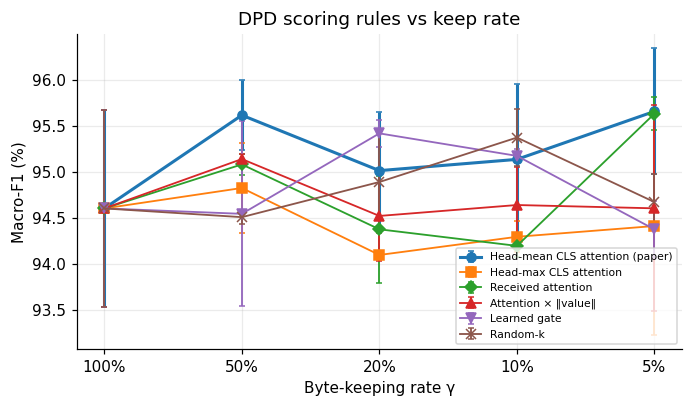

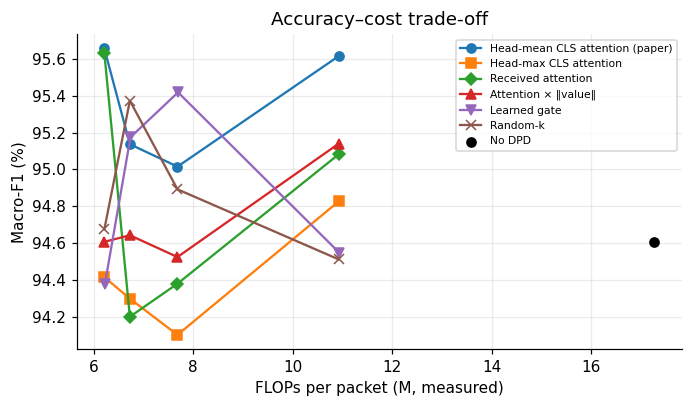

Interpretation guide: differences smaller than the seed std are NOT evidence; report them as ties.


In [ ]:
VARIANTS = ['head_mean', 'head_max', 'col_mean', 'value_norm', 'learned_gate', 'random']
VAR_LABEL = {'head_mean': 'Head-mean CLS attention (paper)', 'head_max': 'Head-max CLS attention', 'col_mean': 'Received attention',
             'value_norm': 'Attention × ‖value‖', 'learned_gate': 'Learned gate', 'random': 'Random-k'}
sweep = []
for seed in CFG['sweep_seeds']:
    sp = make_split('segment', seed)
    seed_all(seed); m = make_model('ut', dict(**UT2, gamma=1.0, scoring='none'))
    r = run_nn(m, X_dev, sp, CFG['sweep_epochs'], seed)
    sweep.append(dict(variant='none', gamma=1.0, seed=seed, f1=r['f1'], acc=r['acc'], flops=measured_flops(m)))
    print(f'seed {seed} | no DPD F1={r["f1"]:.4f}')
    for var in VARIANTS:
        for gm in CFG['keep_rates']:
            seed_all(seed); m = make_model('ut', dict(**UT2, gamma=gm, scoring=var))
            r = run_nn(m, X_dev, sp, CFG['sweep_epochs'], seed)
            sweep.append(dict(variant=var, gamma=gm, seed=seed, f1=r['f1'], acc=r['acc'], flops=measured_flops(m)))
            print(f'seed {seed} | {var:12s} γ={gm:<4} F1={r["f1"]:.4f} acc={r["acc"]:.4f}')
sw = pd.DataFrame(sweep); sw.to_csv(f'{TAB}/table3_sweep_raw.csv', index=False)
ref = sw[sw.variant == 'none']; ref_m, ref_s = ref.f1.mean(), ref.f1.std() if len(ref) > 1 else 0.0
ref_fl = ref.flops.mean()
piv_m = sw[sw.variant != 'none'].pivot_table(index='variant', columns='gamma', values='f1', aggfunc='mean').reindex(VARIANTS)
piv_s = sw[sw.variant != 'none'].pivot_table(index='variant', columns='gamma', values='f1', aggfunc='std').reindex(VARIANTS).fillna(0)
t3 = pd.DataFrame({'Scoring rule': [VAR_LABEL[v] for v in piv_m.index]})
for gm in piv_m.columns: t3[f'γ={round(gm*100)}% F1 (%)'] = [f'{100*piv_m.loc[v, gm]:.2f} ± {100*piv_s.loc[v, gm]:.2f}' for v in piv_m.index]
fl_row = {'Scoring rule': 'FLOPs/pkt (M, measured)'}
for gm in piv_m.columns: fl_row[f'γ={round(gm*100)}% F1 (%)'] = f'{sw[(sw.gamma == gm)].flops.mean()/1e6:.3f}'
fl_row2 = {'Scoring rule': f'No DPD: F1 = {100*ref_m:.2f} ± {100*ref_s:.2f}'}
for gm in piv_m.columns: fl_row2[f'γ={round(gm*100)}% F1 (%)'] = f'(FLOPs {ref_fl/1e6:.3f} M)' if gm == piv_m.columns[0] else ''
t3 = pd.concat([t3, pd.DataFrame([fl_row, fl_row2])], ignore_index=True)
save_table(t3, 'table3_scoring_rules')

xs = [1.0] + list(CFG['keep_rates'])
fig, ax = plt.subplots(figsize=(6.4, 3.8))
for v, mk in zip(VARIANTS, 'osD^vx'):
    ys_ = [ref_m] + [piv_m.loc[v, g_] for g_ in CFG['keep_rates']]; es = [ref_s] + [piv_s.loc[v, g_] for g_ in CFG['keep_rates']]
    ax.errorbar(range(len(xs)), np.array(ys_) * 100, yerr=np.array(es) * 100, marker=mk, capsize=2, label=VAR_LABEL[v], lw=2 if v == 'head_mean' else 1.2)
ax.set_xticks(range(len(xs))); ax.set_xticklabels([f'{round(x*100)}%' for x in xs]); ax.set_xlabel('Byte-keeping rate γ'); ax.set_ylabel('Macro-F1 (%)')
ax.set_title('DPD scoring rules vs keep rate'); ax.legend(fontsize=7); savefig('fig05_scoring_sweep')

fig, ax = plt.subplots(figsize=(6.4, 3.8))
for v, mk in zip(VARIANTS, 'osD^vx'):
    sub = sw[sw.variant == v].groupby('gamma').agg(f1=('f1', 'mean'), fl=('flops', 'mean')).sort_index()
    ax.plot(sub.fl / 1e6, sub.f1 * 100, marker=mk, label=VAR_LABEL[v])
ax.scatter([ref_fl / 1e6], [ref_m * 100], color='k', zorder=5, label='No DPD')
ax.set_xlabel('FLOPs per packet (M, measured)'); ax.set_ylabel('Macro-F1 (%)'); ax.set_title('Accuracy–cost trade-off'); ax.legend(fontsize=7)
savefig('fig06_f1_vs_flops')
print('Interpretation guide: differences smaller than the seed std are NOT evidence; report them as ties.')

## 8. Novelty 2 — leakage-aware evaluation (Table 4, Fig 7)

Same models, three protocols, **identical class set** (classes with ≥ 2 captures) so the numbers are comparable.

seed 0 | packet   UTFormer F1=0.9661 | RF F1=0.9851
seed 0 | segment  UTFormer F1=0.9641 | RF F1=0.9871
seed 0 | capture  UTFormer F1=0.8060 | RF F1=0.7792
seed 1 | packet   UTFormer F1=0.9656 | RF F1=0.9863
seed 1 | segment  UTFormer F1=0.9567 | RF F1=0.9873
seed 1 | capture  UTFormer F1=0.6963 | RF F1=0.7952
seed 2 | packet   UTFormer F1=0.9720 | RF F1=0.9912
seed 2 | segment  UTFormer F1=0.9676 | RF F1=0.9862
seed 2 | capture  UTFormer F1=0.5359 | RF F1=0.6869


,Model,Protocol,Accuracy (%),Macro-F1 (%)
0,RF,packet,98.71 ± 0.33,98.75 ± 0.32
1,RF,segment,98.66 ± 0.08,98.69 ± 0.06
2,RF,capture,69.67 ± 4.38,75.38 ± 5.84
3,UTFormer 2L,packet,96.73 ± 0.36,96.79 ± 0.36
4,UTFormer 2L,segment,96.26 ± 0.54,96.28 ± 0.56
5,UTFormer 2L,capture,65.40 ± 14.72,67.94 ± 13.58


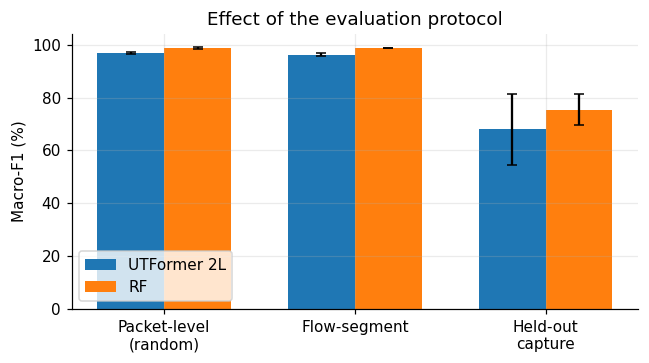

Inflation of packet-level over flow-segment: 0.51 F1 points; over held-out capture: 28.85 points


In [ ]:
leak = []
if len(ELIG) >= 2:
    for seed in CFG['seeds']:
        for prot in ('packet', 'segment', 'capture'):
            sp = make_split(prot, seed, keep_classes=ELIG)
            if len(sp[2]) == 0 or len(sp[0]) == 0: print('empty split for', prot); continue
            seed_all(seed); r = run_nn(make_model('ut', dict(**UT2, gamma=CFG['main_gamma'], scoring='head_mean')), X_dev, sp, CFG['epochs'], seed)
            leak.append(dict(model='UTFormer 2L', protocol=prot, seed=seed, f1=r['f1'], acc=r['acc'], val_f1=r['val_f1']))
            rf = run_rf(sp, seed); leak.append(dict(model='RF', protocol=prot, seed=seed, f1=rf['f1'], acc=rf['acc'], val_f1=float('nan')))
            print(f'seed {seed} | {prot:8s} UTFormer F1={r["f1"]:.4f} | RF F1={rf["f1"]:.4f}')
    lk = pd.DataFrame(leak); lk.to_csv(f'{TAB}/table4_leakage_raw.csv', index=False)
    g_ = lk.groupby(['model', 'protocol'])[['acc', 'f1']].agg(['mean', 'std']).fillna(0)
    rows = []
    for (mdl, prot), r_ in g_.iterrows():
        rows.append({'Model': mdl, 'Protocol': prot, 'Accuracy (%)': f'{100*r_[("acc","mean")]:.2f} ± {100*r_[("acc","std")]:.2f}',
                     'Macro-F1 (%)': f'{100*r_[("f1","mean")]:.2f} ± {100*r_[("f1","std")]:.2f}'})
    t4 = pd.DataFrame(rows); order = {'packet': 0, 'segment': 1, 'capture': 2}
    t4 = t4.sort_values(by=['Model', 'Protocol'], key=lambda s: s.map(order) if s.name == 'Protocol' else s).reset_index(drop=True)
    save_table(t4, 'table4_leakage')
    fig, ax = plt.subplots(figsize=(6, 3.4)); w = .35
    for k, mdl in enumerate(['UTFormer 2L', 'RF']):
        mu = [g_.loc[(mdl, p_), ('f1', 'mean')] * 100 for p_ in order]; sd = [g_.loc[(mdl, p_), ('f1', 'std')] * 100 for p_ in order]
        ax.bar(np.arange(3) + (k - .5) * w, mu, w, yerr=sd, capsize=3, label=mdl)
    ax.set_xticks(range(3)); ax.set_xticklabels(['Packet-level\n(random)', 'Flow-segment', 'Held-out\ncapture']); ax.set_ylabel('Macro-F1 (%)')
    ax.set_title('Effect of the evaluation protocol'); ax.legend(); savefig('fig07_leakage')
    p_ = lk[lk.model == 'UTFormer 2L'].groupby('protocol').f1.mean()
    print(f"Inflation of packet-level over flow-segment: {100*(p_['packet']-p_['segment']):.2f} F1 points; over held-out capture: {100*(p_['packet']-p_['capture']):.2f} points")
else:
    print('Fewer than 2 classes have >= 2 captures: leakage study skipped. Add NonVPN archives (archive_scope=\"both\").')

## 9. Novelty 3 — header reliance (Table 5, Fig 8)

Bytes are zeroed in **both training and test** inputs. IP addresses and ports are already masked in pre-processing, so what remains in the headers is length/flags/TTL/sequence-type structure.

seed 0 | Full input                     F1=0.9547
seed 0 | Mask IP header [0,20)          F1=0.9575
seed 0 | Mask IP+L4 header [0,40)       F1=0.9383
seed 0 | Mask first 96 B                F1=0.4862
seed 0 | Headers only (mask [40,end))   F1=0.9189
seed 1 | Full input                     F1=0.9456
seed 1 | Mask IP header [0,20)          F1=0.9292
seed 1 | Mask IP+L4 header [0,40)       F1=0.9281
seed 1 | Mask first 96 B                F1=0.5016
seed 1 | Headers only (mask [40,end))   F1=0.9341


,Setting,Accuracy (%),Macro-F1 (%),ΔF1 vs full (pts)
0,Full input,94.82 ± 0.67,95.02 ± 0.64,+0.00
1,"Mask IP header [0,20)",94.16 ± 2.01,94.33 ± 2.00,-0.68
2,"Mask IP+L4 header [0,40)",92.84 ± 0.75,93.32 ± 0.72,-1.70
3,Mask first 96 B,54.87 ± 0.72,49.39 ± 1.09,-45.62
4,"Headers only (mask [40,end))",92.40 ± 0.97,92.65 ± 1.08,-2.36


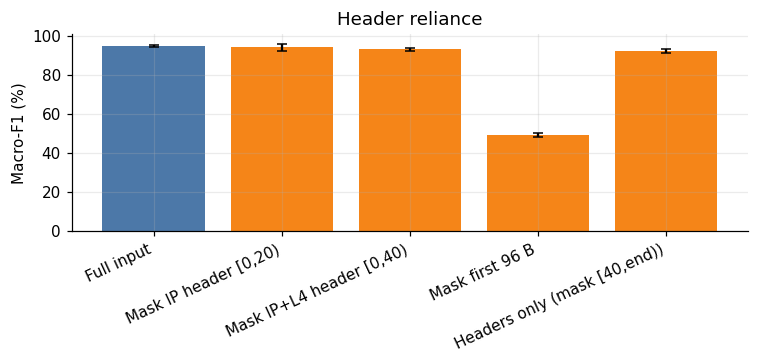

In [ ]:
L_ = CFG['pkt_len']
MASKS = [('Full input', None), ('Mask IP header [0,20)', (0, 20)), ('Mask IP+L4 header [0,40)', (0, 40)),
         ('Mask first 96 B', (0, 96)), ('Headers only (mask [40,end))', (40, L_))]
hdr = []
for seed in CFG['sweep_seeds']:
    sp = make_split('segment', seed)
    for name, rg in MASKS:
        Xm = X_dev if rg is None else X_dev.clone()
        if rg is not None: Xm[:, rg[0]:rg[1]] = 0
        seed_all(seed); r = run_nn(make_model('ut', dict(**UT2, gamma=CFG['main_gamma'], scoring='head_mean')), Xm, sp, CFG['sweep_epochs'], seed)
        hdr.append(dict(setting=name, seed=seed, f1=r['f1'], acc=r['acc'])); print(f'seed {seed} | {name:30s} F1={r["f1"]:.4f}')
        if rg is not None: del Xm
hd = pd.DataFrame(hdr); hd.to_csv(f'{TAB}/table5_header_raw.csv', index=False)
ga = hd.groupby('setting', sort=False)[['acc', 'f1']].agg(['mean', 'std']).fillna(0)
base_f1 = ga.loc['Full input', ('f1', 'mean')]
t5 = pd.DataFrame({'Setting': ga.index, 'Accuracy (%)': [f'{100*ga.loc[s,("acc","mean")]:.2f} ± {100*ga.loc[s,("acc","std")]:.2f}' for s in ga.index],
                   'Macro-F1 (%)': [f'{100*ga.loc[s,("f1","mean")]:.2f} ± {100*ga.loc[s,("f1","std")]:.2f}' for s in ga.index],
                   'ΔF1 vs full (pts)': [f'{100*(ga.loc[s,("f1","mean")]-base_f1):+.2f}' for s in ga.index]})
save_table(t5, 'table5_header_reliance')
fig, ax = plt.subplots(figsize=(7, 3.4))
ax.bar(range(len(ga)), ga[('f1', 'mean')] * 100, yerr=ga[('f1', 'std')] * 100, capsize=3, color=['#4c78a8'] + ['#f58518'] * (len(ga) - 1))
ax.set_xticks(range(len(ga))); ax.set_xticklabels(ga.index, rotation=25, ha='right'); ax.set_ylabel('Macro-F1 (%)'); ax.set_title('Header reliance')
savefig('fig08_header_reliance')

## 10. Explainability

All analyses use the **same importance signal DPD uses** (class-token attention of the first block), plus an independent gradient-based attribution (Integrated Gradients) as a cross-check, because attention is not automatically an explanation.

Token *i* covers bytes `16·i … 16·i+15`. IP addresses and ports are masked, so IP header importance reflects length/TTL/flags rather than endpoints.

In [ ]:
# ---- numpy helpers (no torch) -------------------------------------------------
REGIONS = ['IP header (0–19 B)', 'L4 header (20–39 B)', 'Early payload (40–167 B)', 'Later payload', 'Padding (beyond packet)']
def trap(yv, xv):
    xv = np.asarray(xv, float); yv = np.asarray(yv, float)
    return float(np.sum((xv[1:] - xv[:-1]) * (yv[1:] + yv[:-1]) / 2))
def rank_rows(a): return np.argsort(np.argsort(a, axis=1), axis=1).astype(float)
def spearman_rows(a, b):
    ra, rb = rank_rows(a), rank_rows(b); ra -= ra.mean(1, keepdims=True); rb -= rb.mean(1, keepdims=True)
    den = np.sqrt((ra ** 2).sum(1) * (rb ** 2).sum(1))
    return float(np.mean((ra * rb).sum(1) / np.maximum(den, 1e-12)))
def topk_mask(a, k):
    idx = np.argsort(-a, axis=1)[:, :k]; m = np.zeros(a.shape, bool); np.put_along_axis(m, idx, True, axis=1); return m
def jaccard_rows(a, b, k):
    ma, mb = topk_mask(a, k), topk_mask(b, k)
    return float(np.mean((ma & mb).sum(1) / np.maximum((ma | mb).sum(1), 1)))
def region_matrix(pl, n_tok, patch=16):
    starts = np.arange(n_tok) * patch; centers = starts + patch / 2
    base = np.select([centers < 20, centers < 40, centers < 168], [0, 1, 2], 3)
    R = np.tile(base, (len(pl), 1)); R[starts[None, :] >= np.asarray(pl)[:, None]] = 4
    return R
def region_mass(scores, R):
    s = scores / np.maximum(scores.sum(1, keepdims=True), 1e-12)
    return np.stack([(s * (R == r)).sum(1) for r in range(5)], 1)
print('helpers ready')

helpers ready


scores: {'head_mean': (600, 94), 'head_max': (600, 94), 'col_mean': (600, 94), 'value_norm': (600, 94)} | kept tokens per packet: 19


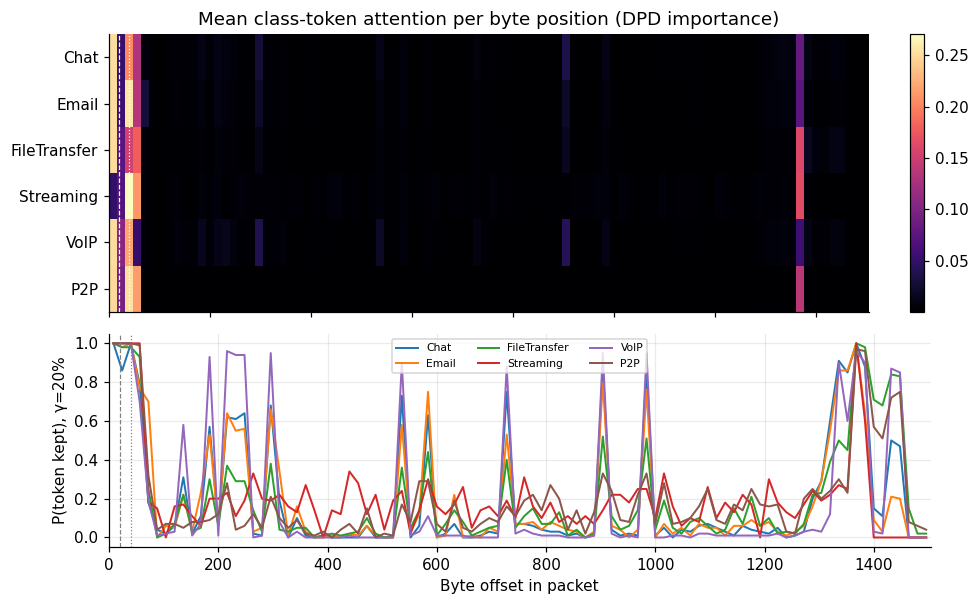

,class,IP header (0–19 B),L4 header (20–39 B),Early payload (40–167 B),Later payload,Padding (beyond packet)
Chat,Chat,0.2519,0.0517,0.3437,0.0204,0.3323
Email,Email,0.2528,0.0560,0.4244,0.0154,0.2514
FileTransfer,FileTransfer,0.2507,0.0731,0.3364,0.0364,0.3034
Streaming,Streaming,0.0493,0.0716,0.4967,0.2099,0.1726
VoIP,VoIP,0.2526,0.1055,0.2751,0.0062,0.3606
P2P,P2P,0.2501,0.0949,0.4727,0.0347,0.1477


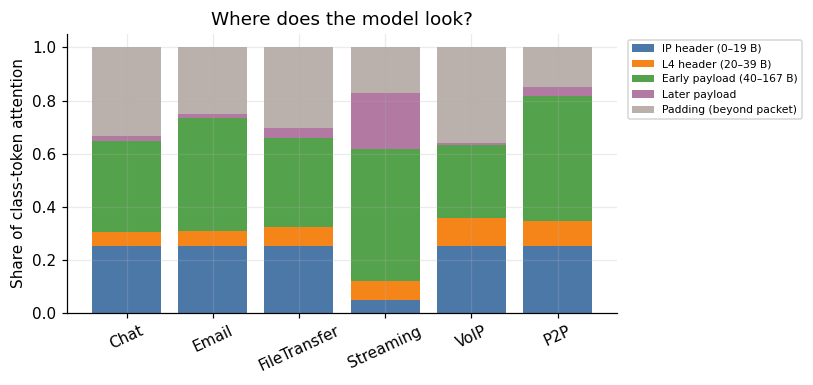

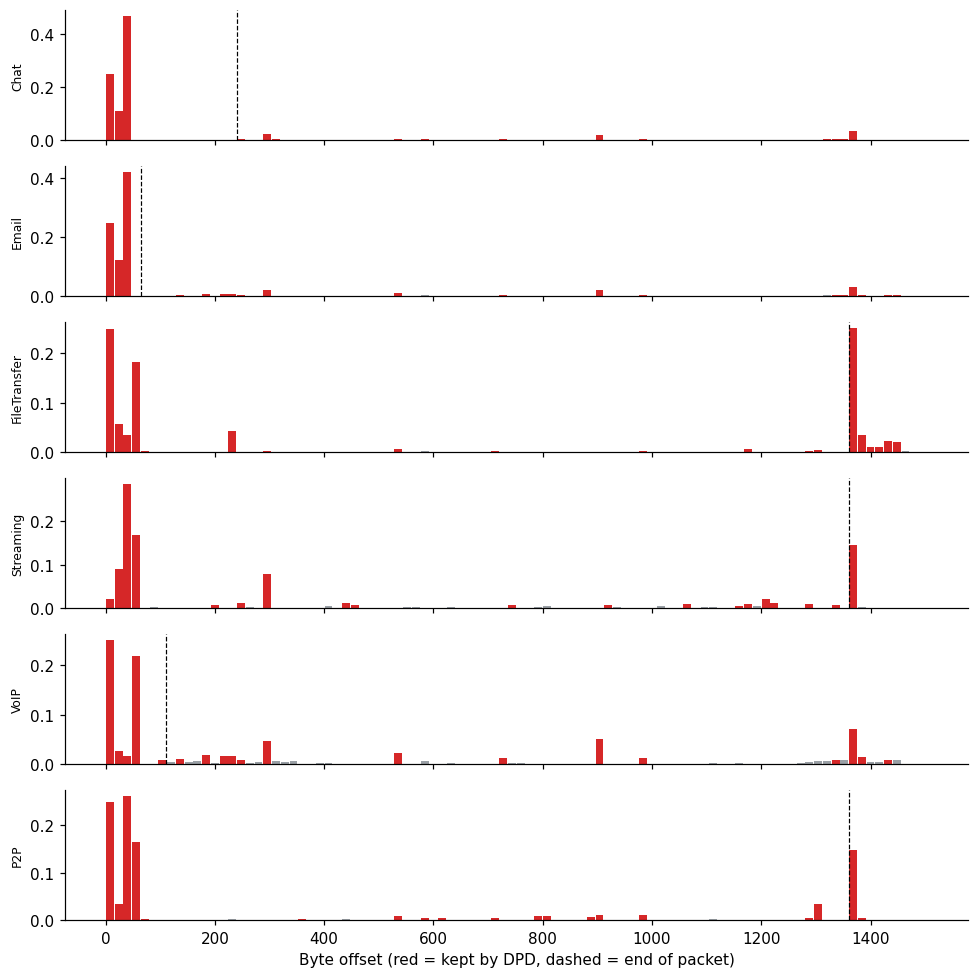

In [ ]:
# ---- samples to explain (stratified test samples of seed 0) -----------------------
m_dpd = MAIN[NAME_DPD]['r']['model']; m_base = MAIN[NAME_BASE]['r']['model']
te0 = MAIN[NAME_DPD]['split'][2]; rs = np.random.RandomState(0); PATCH = CFG['patch']
sel = np.concatenate([rs.choice(te0[y[te0] == c], min(CFG['n_explain_per_class'], int((y[te0] == c).sum())), replace=False)
                      for c in range(NC) if (y[te0] == c).sum() > 0])
y_sel, plen_sel = y[sel], plen[sel]; R_sel = region_matrix(plen_sel, NTOK, PATCH)
sel_t = torch.as_tensor(sel, device=DEVICE)

@torch.no_grad()
def collect_scores(model, idx_t, bs=256):
    model.eval(); outs = {k: [] for k in ('head_mean', 'head_max', 'col_mean', 'value_norm')}; keeps = []
    for i in range(0, len(idx_t), bs):
        xb = X_dev[idx_t[i:i + bs]].float() / 256
        _, info = model(xb, return_info=True)
        a, v = info['attn0'].float(), info['v0'].float()
        for k in outs: outs[k].append(token_scores(k, a, v).float().cpu())
        if 'keep_idx' in info: keeps.append(info['keep_idx'].cpu())
    return {k: torch.cat(v).numpy() for k, v in outs.items()}, (torch.cat(keeps).numpy() if keeps else None)

S_dpd, KEEP_dpd = collect_scores(m_dpd, sel_t)
S_base, _ = collect_scores(m_base, sel_t)
print('scores:', {k: v.shape for k, v in S_dpd.items()}, '| kept tokens per packet:', None if KEEP_dpd is None else KEEP_dpd.shape[1])

# ---- Fig 9: per-class importance heatmap + keep frequency -------------------------
sn = S_dpd['head_mean'] / np.maximum(S_dpd['head_mean'].sum(1, keepdims=True), 1e-12)
heat = np.stack([sn[y_sel == c].mean(0) for c in range(NC)])
keepfreq = np.zeros((NC, NTOK))
if KEEP_dpd is not None:
    for c in range(NC):
        for row in KEEP_dpd[y_sel == c]: keepfreq[c, row] += 1
        keepfreq[c] /= max((y_sel == c).sum(), 1)
fig, ax = plt.subplots(2, 1, figsize=(9, 5.6), sharex=True, gridspec_kw={'height_ratios': [1.3, 1]})
im = ax[0].imshow(heat, aspect='auto', cmap='magma', extent=[0, NTOK * PATCH, NC, 0]); ax[0].grid(False)
ax[0].set_yticks(np.arange(NC) + .5); ax[0].set_yticklabels(CLASS_NAMES); ax[0].set_title('Mean class-token attention per byte position (DPD importance)')
plt.colorbar(im, ax=ax[0], fraction=.025)
for c in range(NC): ax[1].plot(np.arange(NTOK) * PATCH + PATCH / 2, keepfreq[c], label=CLASS_NAMES[c], lw=1.3)
ax[1].set_ylabel(f'P(token kept), γ={CFG["main_gamma"]:.0%}'); ax[1].set_xlabel('Byte offset in packet'); ax[1].legend(ncol=3, fontsize=7)
for a_ in ax:
    a_.axvline(20, color='w' if a_ is ax[0] else 'gray', ls='--', lw=.8); a_.axvline(40, color='w' if a_ is ax[0] else 'gray', ls=':', lw=.8)
savefig('fig09_heatmap_class')

# ---- Fig 10 / Table 6: importance mass per protocol region ------------------------
rm = region_mass(S_dpd['head_mean'], R_sel)
t6 = pd.DataFrame([rm[y_sel == c].mean(0) for c in range(NC)], columns=REGIONS, index=CLASS_NAMES).round(4)
t6.insert(0, 'class', CLASS_NAMES); save_table(t6, 'table6_region_mass')
fig, ax = plt.subplots(figsize=(7.5, 3.6)); bottom = np.zeros(NC)
for r_, col in zip(range(5), ['#4c78a8', '#f58518', '#54a24b', '#b279a2', '#bab0ac']):
    vals = t6[REGIONS[r_]].values; ax.bar(CLASS_NAMES, vals, bottom=bottom, label=REGIONS[r_], color=col); bottom += vals
ax.set_ylabel('Share of class-token attention'); ax.set_title('Where does the model look?'); ax.legend(fontsize=7, bbox_to_anchor=(1.01, 1), loc='upper left')
plt.xticks(rotation=25); savefig('fig10_region_mass')

# ---- Fig 11: kept tokens for one packet per class --------------------------------
fig, axs = plt.subplots(NC, 1, figsize=(9, 1.5 * NC), sharex=True); axs = np.atleast_1d(axs)
for c in range(NC):
    ii = np.where(y_sel == c)[0]
    if len(ii) == 0: continue
    i0 = ii[0]; s = S_dpd['head_mean'][i0]; kept = np.zeros(NTOK, bool)
    if KEEP_dpd is not None: kept[KEEP_dpd[i0]] = True
    axs[c].bar(np.arange(NTOK) * PATCH + PATCH / 2, s, width=PATCH * .9, color=np.where(kept, '#d62728', '#9aa0a6'))
    axs[c].axvline(plen_sel[i0], color='k', ls='--', lw=.8); axs[c].set_ylabel(CLASS_NAMES[c], fontsize=8); axs[c].grid(False)
axs[-1].set_xlabel('Byte offset (red = kept by DPD, dashed = end of packet)'); savefig('fig11_kept_examples')

## 11. Faithfulness (deletion / insertion) and agreement between importance rules

* **Deletion** — zero the top-q % tokens of a ranking and measure accuracy (a faithful ranking makes accuracy fall *fast*; lower AUC is better).
* **Insertion** — start from an all-zero packet and add the top-q % tokens (a faithful ranking makes accuracy rise *fast*; higher AUC is better).
* Rankings come from the **undistilled 2-layer model** so every rule is judged on the same network. `random` is the control. "Padding in top-20 %" shows how much budget a rule wastes on empty tokens.

Integrated Gradients done (0s)


,Rule,"Deletion AUC (acc, ↓)","Insertion AUC (acc, ↑)","Deletion AUC (true-class prob, ↓)","Insertion AUC (true-class prob, ↑)",Padding in top-20% (%)
0,Head-mean (paper),0.1697,0.6349,0.1831,0.6158,42.9386
1,Head-max,0.1762,0.6389,0.1882,0.6206,42.3772
2,Received attn,0.4472,0.5011,0.4374,0.4919,26.8421
3,Attn × ‖v‖,0.1706,0.6698,0.1846,0.6537,41.0439
4,Integrated Grad.,0.1938,0.8713,0.2000,0.8545,24.1579
5,Random,0.4680,0.3812,0.4595,0.3754,46.9211


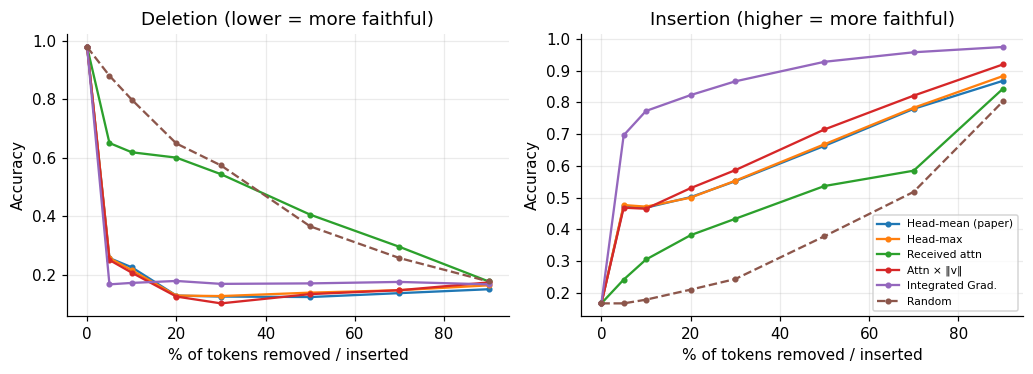

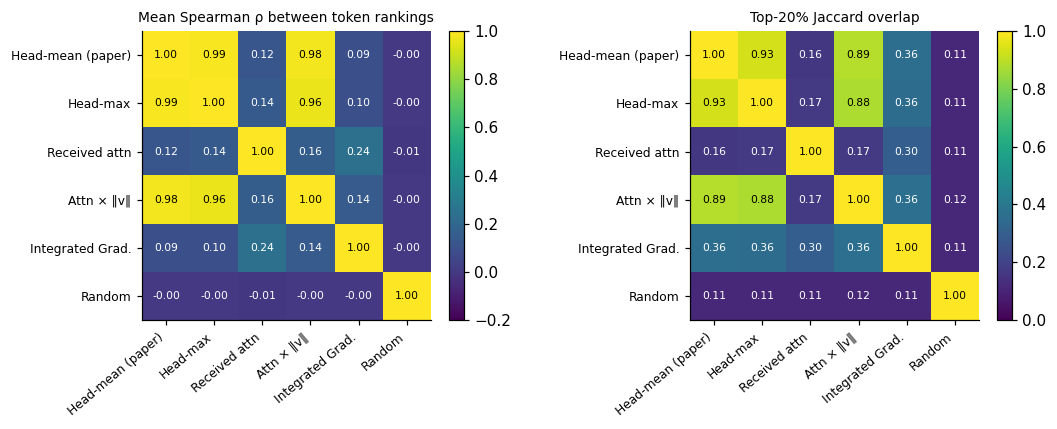

In [ ]:
def integrated_gradients(model, xs, ys, steps):
    model.eval(); out = []
    for i in range(0, len(xs), 128):
        xb, yb = xs[i:i + 128], ys[i:i + 128]; tot = torch.zeros_like(xb)
        for k in range(1, steps + 1):
            xi = (xb * (k / steps)).clone().requires_grad_(True)
            g, = torch.autograd.grad(model(xi).gather(1, yb[:, None]).sum(), xi); tot += g
        attr = (tot / steps * xb).abs()
        out.append(F.pad(attr, (0, m_base.pad)).reshape(len(xb), NTOK, PATCH).sum(-1).detach().cpu())
    return torch.cat(out).numpy()

xs_sel = X_dev[sel_t].float() / 256; ys_sel = y_dev[sel_t]
t0 = time.time(); S_ig = integrated_gradients(m_base, xs_sel, ys_sel, CFG['ig_steps']); print(f'Integrated Gradients done ({time.time()-t0:.0f}s)')
METHODS = {'head_mean': S_base['head_mean'], 'head_max': S_base['head_max'], 'col_mean': S_base['col_mean'],
           'value_norm': S_base['value_norm'], 'int_grad': S_ig, 'random': np.random.RandomState(1).rand(len(sel), NTOK)}
M_LABEL = {'head_mean': 'Head-mean (paper)', 'head_max': 'Head-max', 'col_mean': 'Received attn', 'value_norm': 'Attn × ‖v‖',
           'int_grad': 'Integrated Grad.', 'random': 'Random'}

@torch.no_grad()
def eval_modified(tok_mask, keep_selected):
    # tok_mask: (N,NTOK) bool numpy; keep_selected=True -> insertion, False -> deletion
    tok = F.pad(xs_sel, (0, m_base.pad)).reshape(len(xs_sel), NTOK, PATCH)
    m = torch.as_tensor(tok_mask, device=DEVICE).unsqueeze(-1).float()
    tok = tok * (m if keep_selected else 1 - m)
    xm = tok.reshape(len(xs_sel), NTOK * PATCH)[:, :CFG['pkt_len']]
    m_base.eval(); logits = torch.cat([m_base(xm[i:i + 512]) for i in range(0, len(xm), 512)])
    pr = torch.softmax(logits, 1)
    return (logits.argmax(1) == ys_sel).float().mean().item(), pr.gather(1, ys_sel[:, None]).mean().item()

QS = [0, .05, .1, .2, .3, .5, .7, .9]
curves = {}
for name, sc in METHODS.items():
    dele, ins = [], []
    for q in QS:
        k = int(round(q * NTOK)); mk = topk_mask(sc, k) if k > 0 else np.zeros(sc.shape, bool)
        dele.append(eval_modified(mk, False)); ins.append(eval_modified(mk, True))
    curves[name] = dict(del_acc=[d[0] for d in dele], del_p=[d[1] for d in dele], ins_acc=[i[0] for i in ins], ins_p=[i[1] for i in ins])

k20 = int(round(.2 * NTOK)); rows = []
for name, sc in METHODS.items():
    c_ = curves[name]; m20 = topk_mask(sc, k20)
    rows.append({'Rule': M_LABEL[name], 'Deletion AUC (acc, ↓)': trap(c_['del_acc'], QS) / QS[-1], 'Insertion AUC (acc, ↑)': trap(c_['ins_acc'], QS) / QS[-1],
                 'Deletion AUC (true-class prob, ↓)': trap(c_['del_p'], QS) / QS[-1], 'Insertion AUC (true-class prob, ↑)': trap(c_['ins_p'], QS) / QS[-1],
                 'Padding in top-20% (%)': 100 * float((m20 & (R_sel == 4)).sum() / max(m20.sum(), 1))})
t7 = save_table(pd.DataFrame(rows).round(4), 'table7_faithfulness')

fig, ax = plt.subplots(1, 2, figsize=(9.5, 3.5))
for name in METHODS:
    ax[0].plot(np.array(QS) * 100, curves[name]['del_acc'], marker='o', ms=3, label=M_LABEL[name], ls='--' if name == 'random' else '-')
    ax[1].plot(np.array(QS) * 100, curves[name]['ins_acc'], marker='o', ms=3, label=M_LABEL[name], ls='--' if name == 'random' else '-')
ax[0].set_title('Deletion (lower = more faithful)'); ax[1].set_title('Insertion (higher = more faithful)')
for a_ in ax: a_.set_xlabel('% of tokens removed / inserted'); a_.set_ylabel('Accuracy')
ax[1].legend(fontsize=7); savefig('fig12_faithfulness')

# ---- agreement between rules (Fig 13) --------------------------------------------
names = list(METHODS); K = len(names); sp_m = np.eye(K); jc_m = np.eye(K)
for i in range(K):
    for j in range(K):
        if i != j: sp_m[i, j] = spearman_rows(METHODS[names[i]], METHODS[names[j]]); jc_m[i, j] = jaccard_rows(METHODS[names[i]], METHODS[names[j]], k20)
fig, ax = plt.subplots(1, 2, figsize=(10, 4))
for a_, M_, tt, vmin in zip(ax, (sp_m, jc_m), ('Mean Spearman ρ between token rankings', 'Top-20% Jaccard overlap'), (-.2, 0)):
    im = a_.imshow(M_, cmap='viridis', vmin=vmin, vmax=1); a_.grid(False); a_.set_title(tt, fontsize=9)
    a_.set_xticks(range(K)); a_.set_xticklabels([M_LABEL[n] for n in names], rotation=40, ha='right', fontsize=8)
    a_.set_yticks(range(K)); a_.set_yticklabels([M_LABEL[n] for n in names], fontsize=8)
    for i in range(K):
        for j in range(K): a_.text(j, i, f'{M_[i,j]:.2f}', ha='center', va='center', color='w' if M_[i, j] < .6 else 'k', fontsize=7)
    plt.colorbar(im, ax=a_, fraction=.046)
savefig('fig13_agreement')
pd.DataFrame(sp_m, index=names, columns=names).round(3).to_csv(f'{TAB}/table8_agreement_spearman.csv')
pd.DataFrame(jc_m, index=names, columns=names).round(3).to_csv(f'{TAB}/table8_agreement_jaccard20.csv')

## 12. Export — auto-generated results summary, ZIP, Drive copy

In [ ]:
def _g(name): return globals().get(name)
L = ['# UTFormer / ISCX-VPN-2016 — auto-generated results summary', '',
     f'Classes ({NC}): {", ".join(CLASS_NAMES)} | packets: {N} | capture files: {len(np.unique(mem))} | archive scope: {scope_used}',
     f'Protocol (main): flow-segment split (seg_len={CFG["seg_len"]}), seeds={CFG["seeds"]}, epochs={CFG["epochs"]}, QUICK={QUICK}', '']
try: _t1 = t1.to_markdown(index=False)
except Exception: _t1 = t1.to_string(index=False)
try:
    L += ['## Differentiable architecture search (Tables 9-11, Figs 14-16)',
          f'Searched architecture (last iterate): {DAS_P}; lowest-unified-loss iterate: {DAS_P_BEST}; iterations run: {len(das_hist)}; alpha={CFG["das_alpha"]}, beta={CFG["das_beta"]}.',
          'Paper-reported ISCX architecture: Nl=1, Nh=4, d=268, gamma=5%.', '']
except Exception: pass
L += ['## Main results (Table 1)', _t1, '']
try:
    L += ['## Efficiency (Table 2)', eff_df.round(3).to_string(index=False), '']
except Exception: pass
try:
    best = {g_: piv_m[g_].idxmax() for g_ in piv_m.columns}
    L += ['## Scoring rules (Table 3)', 'Best rule per keep rate: ' + ', '.join(f'γ={round(g_*100)}% -> {VAR_LABEL[b]} ({100*piv_m.loc[b,g_]:.2f})' for g_, b in best.items()),
          f'Head-mean (paper) vs best, F1 pts: ' + ', '.join(f'γ={round(g_*100)}%: {100*(piv_m.loc[b,g_]-piv_m.loc["head_mean",g_]):+.2f}' for g_, b in best.items()),
          'Treat differences below the seed std as ties.', '']
except Exception: pass
try:
    p_ = lk[lk.model == 'UTFormer 2L'].groupby('protocol').f1.mean()
    L += ['## Leakage-aware evaluation (Table 4)', f'UTFormer F1: packet {100*p_["packet"]:.2f}, segment {100*p_["segment"]:.2f}, capture {100*p_["capture"]:.2f} '
          f'-> packet-level inflation {100*(p_["packet"]-p_["segment"]):.2f} pts over segment, {100*(p_["packet"]-p_["capture"]):.2f} pts over held-out capture.', '']
except Exception: pass
try:
    worst = ga[('f1', 'mean')].drop('Full input').idxmin()
    L += ['## Header reliance (Table 5)', f'Largest drop: "{worst}" ({100*(ga.loc[worst,("f1","mean")]-base_f1):+.2f} F1 pts vs full input).', '']
except Exception: pass
try:
    L += ['## Explainability', 'Top region per class (share of class-token attention): ' + '; '.join(f'{c}: {t6.loc[c, REGIONS].astype(float).idxmax()}' for c in CLASS_NAMES),
          'Faithfulness (deletion AUC, lower is better): ' + ', '.join(f'{r["Rule"]} {r["Deletion AUC (acc, ↓)"]:.3f}' for _, r in t7.iterrows()), '']
except Exception: pass
L += ['## Reference (paper, ISCX-VPN 6 classes, different data/split): accuracy 94.35 %, F1 93.24 %, 156 KB, ~241.8 kFLOPs', '',
      '## Deviations to disclose', '- DAS: validation-loss gradient estimated with SPSA, normalised-step SGD (paper lr=0.005 did not move the parameters), search on a training subset, heads snapped to divisors of the embedding size.',
      '- Flow-segment instead of whole-flow split; packet/segment sampling caps per capture and per class.',
      '- Reduced epochs/seeds; offline throughput only (no DPDK 10 Gbps testbed).',
      '- Eq. 8 of the paper multiplies the bracket by γ although C_Aγ and C_F already contain γ; both variants are reported.']
open(f'{OUT}/results_summary.md', 'w').write('\n'.join(L))
json.dump({k: v for k, v in CFG.items()}, open(f'{OUT}/config.json', 'w'), indent=2, default=str)

zip_path = shutil.make_archive('/content/UTFormer_Novelty_Results', 'zip', OUT)
print('Figures:', sorted(os.listdir(FIG))); print('Tables :', sorted(os.listdir(TAB))); print('ZIP    :', zip_path)
if IN_COLAB:
    try:
        shutil.copytree(OUT, '/content/drive/MyDrive/UTFormer_Novelty_Results', dirs_exist_ok=True); print('Copied to Drive: MyDrive/UTFormer_Novelty_Results')
    except Exception as e: print('Drive copy failed:', e)
    try:
        from google.colab import files; files.download(zip_path)
    except Exception as e: print('Download skipped:', e)
print('\n'.join(L[:12]))

Figures: ['fig01_dataset.pdf', 'fig01_dataset.png', 'fig02_main_f1_bars.pdf', 'fig02_main_f1_bars.png', 'fig03_training_curves.pdf', 'fig03_training_curves.png', 'fig04_confusion.pdf', 'fig04_confusion.png', 'fig05_scoring_sweep.pdf', 'fig05_scoring_sweep.png', 'fig06_f1_vs_flops.pdf', 'fig06_f1_vs_flops.png', 'fig07_leakage.pdf', 'fig07_leakage.png', 'fig08_header_reliance.pdf', 'fig08_header_reliance.png', 'fig09_heatmap_class.pdf', 'fig09_heatmap_class.png', 'fig10_region_mass.pdf', 'fig10_region_mass.png', 'fig11_kept_examples.pdf', 'fig11_kept_examples.png', 'fig12_faithfulness.pdf', 'fig12_faithfulness.png', 'fig13_agreement.pdf', 'fig13_agreement.png', 'fig14_das_convergence.pdf', 'fig14_das_convergence.png', 'fig15_das_parameters.pdf', 'fig15_das_parameters.png', 'fig16_das_coefficients.pdf', 'fig16_das_coefficients.png']
Tables : ['table0_dataset.csv', 'table0_dataset.tex', 'table10_das_architectures.csv', 'table10_das_architectures.tex', 'table11_das_coefficients.csv', 'table

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

# UTFormer / ISCX-VPN-2016 — auto-generated results summary

Classes (6): Chat, Email, FileTransfer, Streaming, VoIP, P2P | packets: 31520 | capture files: 31 | archive scope: vpn
Protocol (main): flow-segment split (seg_len=100), seeds=[0, 1, 2], epochs=20, QUICK=False

## Differentiable architecture search (Tables 9-11, Figs 14-16)
Searched architecture (last iterate): {'Nh': 1, 'Nl': 1, 'd': 338, 'gamma': 0.422}; lowest-unified-loss iterate: {'Nh': 2, 'Nl': 1, 'd': 377, 'gamma': 0.44}; iterations run: 15; alpha=0.5, beta=1.5.
Paper-reported ISCX architecture: Nl=1, Nh=4, d=268, gamma=5%.

## Main results (Table 1)
| Model                         | Accuracy (%)   | Precision (%)   | Recall (%)   | F1 (%)       |
|:------------------------------|:---------------|:----------------|:-------------|:-------------|
| RF (stats + first 64 B)       | 98.80 ± 0.05   | 98.85 ± 0.06    | 98.89 ± 0.01 | 98.87 ± 0.04 |
| 1D-CNN                        | 72.36 ± 0.28   | 78.40 ± 2.29    | 71.69 ± 1